In [1]:
!pip install yfinance pandas numpy lxml requests pyarrow

In [2]:
import pandas as pd
import numpy as np
import yfinance as yf
import requests
from datetime import datetime

In [3]:
#Task 1 Data Preparation and Feature Engineering
#Question 1.1

In [4]:
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
retrieval_date = datetime.now().strftime("%Y-%m-%d")

# Extract the S&P 500 constituents table
headers = {"User-Agent": "Mozilla/5.0"}
response = requests.get(url, headers=headers, timeout=30)
response.raise_for_status()
tables = pd.read_html(response.text)

# Select the company constituents table
sp500 = tables[0]

# Select relevant columns
sp500 = sp500[["Symbol", "Security", "GICS Sector"]]

# Convert ticker symbols to Yahoo Finance format
sp500["Yahoo_Ticker"] = sp500["Symbol"].str.replace(".", "-", regex=False)

# Display the first five companies
print("Retrieval Date:", retrieval_date)
print("Total S&P 500 companies:", len(sp500))

display(sp500.head())

/tmp/ipykernel_1550/845844400.py:8: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(response.text)


Retrieval Date: 2026-11-22
Total S&P 500 companies: 503


/tmp/ipykernel_1550/845844400.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sp500["Yahoo_Ticker"] = sp500["Symbol"].str.replace(".", "-", regex=False)


,Symbol,Security,GICS Sector,Yahoo_Ticker
0,MMM,3M,Industrials,MMM
1,AOS,A. O. Smith,Industrials,AOS
2,ABT,Abbott Laboratories,Health Care,ABT
3,ABBV,AbbVie,Health Care,ABBV
4,ACN,Accenture,Information Technology,ACN


In [5]:
# Save ticker list
sp500.to_csv("sp500_tickers.csv", index=False)

print("Ticker list saved successfully!")
print("Number of companies:", len(sp500))

Ticker list saved successfully!
Number of companies: 503


In [6]:
import time

start_date = "2021-01-01"
end_date = "2025-01-01"
tickers = sp500["Yahoo_Ticker"].tolist()

# Store downloaded stock data
stock_data = {}

# Store tickers that could not be downloaded
failed_tickers = []

# Download stocks in batches
batch_size = 40

for i in range(0, len(tickers), batch_size):

    batch = tickers[i:i + batch_size]

    print(f"Downloading batch {i//batch_size + 1} "
          f"of {(len(tickers)-1)//batch_size + 1}")

    try:
        data = yf.download(
            batch,
            start=start_date,
            end=end_date,
            interval="1d",
            auto_adjust=False,
            actions=True,
            group_by="ticker",
            threads=True,
            progress=False)

        for ticker in batch:

            try:
                if isinstance(data.columns, pd.MultiIndex):

                    if ticker in data.columns.get_level_values(0):
                        df = data[ticker].copy()

                    elif ticker in data.columns.get_level_values(1):
                        df = data.xs(ticker, axis=1, level=1).copy()

                    else:
                        failed_tickers.append(ticker)
                        continue

                else:
                    if len(batch) == 1:
                        df = data.copy()
                    else:
                        failed_tickers.append(ticker)
                        continue

                if "Close" not in df.columns or df["Close"].dropna().empty:
                    failed_tickers.append(ticker)
                    continue

                df = df.reset_index()
                df["Ticker"] = ticker

                stock_data[ticker] = df

            except Exception:
                failed_tickers.append(ticker)

    except Exception as e:
        print("Batch error:", e)
        failed_tickers.extend(batch)

    time.sleep(2)

print("\nDownload completed!")
print("Successfully downloaded:", len(stock_data))
print("Failed tickers:", len(set(failed_tickers)))

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')



Download completed!
Successfully downloaded: 498
Failed tickers: 5


In [7]:
# Download S&P 500 benchmark data
benchmark = yf.download(
    "^GSPC",
    start="2021-01-01",
    end="2025-01-01",
    interval="1d",
    auto_adjust=False,
    actions=True,
    progress=False)

benchmark = benchmark.reset_index()
display(benchmark.head())

Price,Date,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Ticker,,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
0,2021-01-04,3700.649902,3700.649902,0.0,3769.989990,3662.709961,3764.610107,0.0,5015000000
1,2021-01-05,3726.860107,3726.860107,0.0,3737.830078,3695.070068,3698.020020,0.0,4591020000
2,2021-01-06,3748.139893,3748.139893,0.0,3783.040039,3705.340088,3712.199951,0.0,6064110000
3,2021-01-07,3803.790039,3803.790039,0.0,3811.550049,3764.709961,3764.709961,0.0,5099160000
4,2021-01-08,3824.679932,3824.679932,0.0,3826.689941,3783.600098,3815.050049,0.0,4773040000


In [8]:
# Combine all downloaded stock data
all_stocks = pd.concat(
    stock_data.values(),
    ignore_index=True)

# Save stock historical data
all_stocks.to_csv("historical_stock_data.csv", index=False)

# Save benchmark data
benchmark.to_csv("benchmark_data.csv", index=False)

# Save failed ticker list for investigation
pd.DataFrame({"Failed_Ticker": sorted(set(failed_tickers))}).to_csv("failed_tickers.csv", index=False)

print("All datasets saved successfully!")
print("Stock records:", len(all_stocks))
print("Benchmark records:", len(benchmark))

All datasets saved successfully!
Stock records: 500490
Benchmark records: 1005


In [9]:
# Record acquisition details and package versions

metadata = pd.DataFrame({
    "Item": [
        "Data Source",
        "Download Library",
        "Ticker Retrieval Date",
        "Study Start Date",
        "Study End Date (Exclusive)",
        "Stock Interval",
        "Python Version",
        "Pandas Version",
        "yfinance Version"],
    "Value": [
        "Yahoo Finance",
        "yfinance",
        retrieval_date,
        start_date,
        end_date,
        "Daily",
        __import__("sys").version.split()[0],
        pd.__version__,
        yf.__version__]})

display(metadata)

metadata.to_csv("acquisition_metadata.csv", index=False)

,Item,Value
0,Data Source,Yahoo Finance
1,Download Library,yfinance
2,Ticker Retrieval Date,2026-11-22
3,Study Start Date,2021-01-01
4,Study End Date (Exclusive),2025-01-01
5,Stock Interval,Daily
6,Python Version,3.13.18
7,Pandas Version,2.2.3
8,yfinance Version,0.2.66


In [10]:
print("STOCK DATA")
display(all_stocks.head())

print("\nBENCHMARK DATA")
display(benchmark.head())

print("\nSTOCK DATA INFORMATION")
print(all_stocks.info())

print("\nFAILED TICKERS")
print(sorted(set(failed_tickers)))

STOCK DATA


Price,Date,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Ticker
0,2021-01-04,146.321075,147.324417,142.600327,143.704010,117.366676,3583455.0,0.0,0.0,MMM
1,2021-01-05,143.821075,144.857864,142.683945,143.461533,117.168633,2745179.0,0.0,0.0,MMM
2,2021-01-06,144.414719,146.797653,143.846161,145.643814,118.950951,4002294.0,0.0,0.0,MMM
3,2021-01-07,143.444809,145.033447,138.929764,141.906357,115.898506,7012626.0,0.0,0.0,MMM
4,2021-01-08,141.446487,141.755859,137.633774,139.314377,113.781570,5750488.0,0.0,0.0,MMM



BENCHMARK DATA


Price,Date,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Ticker,,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
0,2021-01-04,3700.649902,3700.649902,0.0,3769.989990,3662.709961,3764.610107,0.0,5015000000
1,2021-01-05,3726.860107,3726.860107,0.0,3737.830078,3695.070068,3698.020020,0.0,4591020000
2,2021-01-06,3748.139893,3748.139893,0.0,3783.040039,3705.340088,3712.199951,0.0,6064110000
3,2021-01-07,3803.790039,3803.790039,0.0,3811.550049,3764.709961,3764.709961,0.0,5099160000
4,2021-01-08,3824.679932,3824.679932,0.0,3826.689941,3783.600098,3815.050049,0.0,4773040000



STOCK DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500490 entries, 0 to 500489
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Date          500490 non-null  datetime64[ns]
 1   Open          496304 non-null  float64       
 2   High          496304 non-null  float64       
 3   Low           496304 non-null  float64       
 4   Close         496304 non-null  float64       
 5   Adj Close     496304 non-null  float64       
 6   Volume        496304 non-null  float64       
 7   Dividends     496304 non-null  float64       
 8   Stock Splits  496304 non-null  float64       
 9   Ticker        500490 non-null  object        
dtypes: datetime64[ns](1), float64(8), object(1)
memory usage: 38.2+ MB
None

FAILED TICKERS
['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


In [11]:
# Question 1.2

In [12]:
# Check the downloaded datasets

print("Stock dataset shape:", all_stocks.shape)
print("Benchmark dataset shape:", benchmark.shape)

print("\nStock dataset columns:")
print(all_stocks.columns.tolist())

print("\nBenchmark dataset columns:")
print(benchmark.columns.tolist())

print("\nNumber of unique shares:",
      all_stocks["Ticker"].nunique())

Stock dataset shape: (500490, 10)
Benchmark dataset shape: (1005, 9)

Stock dataset columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits', 'Ticker']

Benchmark dataset columns:
[('Date', ''), ('Adj Close', '^GSPC'), ('Close', '^GSPC'), ('Dividends', '^GSPC'), ('High', '^GSPC'), ('Low', '^GSPC'), ('Open', '^GSPC'), ('Stock Splits', '^GSPC'), ('Volume', '^GSPC')]

Number of unique shares: 498


In [13]:
# Flatten MultiIndex columns of benchmark if they exist
if isinstance(benchmark.columns, pd.MultiIndex):
    benchmark.columns = [col[0] if col[1] == '' else col[0] for col in benchmark.columns]

# Convert Date column into datetime format
all_stocks["Date"] = pd.to_datetime(all_stocks["Date"])
benchmark["Date"] = pd.to_datetime(benchmark["Date"])

# Check duplicate ticker and date combinations
duplicate_stocks = all_stocks[
    all_stocks.duplicated(
        subset=["Ticker", "Date"],
        keep=False
    )
]

duplicate_benchmark = benchmark[
    benchmark.duplicated(
        subset=["Date"],
        keep=False
    )
]

print("Duplicate stock records:",
      len(duplicate_stocks))

print("Duplicate benchmark records:",
      len(duplicate_benchmark))

Duplicate stock records: 0
Duplicate benchmark records: 0


In [14]:
# Important columns
important_columns = [
    "Close",
    "Adj Close",
    "Volume"]

# Check missing values in stock data
print("Missing values in stock data:")

display(
    all_stocks.groupby("Ticker")[important_columns]
    .apply(lambda x: x.isnull().sum()))

# Check missing values in benchmark data
print("\nMissing values in benchmark data:")

print(
    benchmark[important_columns].isnull().sum())

Missing values in stock data:


Price,Close,Adj Close,Volume
Ticker,,,
A,0,0,0
AAPL,0,0,0
ABBV,0,0,0
ABNB,0,0,0
ABT,0,0,0
...,...,...,...
XYZ,0,0,0
YUM,0,0,0
ZBH,0,0,0



Missing values in benchmark data:
Close        0
Adj Close    0
Volume       0
dtype: int64


In [15]:
# Check for zero or negative prices
price_columns = ["Close", "Adj Close"]
invalid_prices = all_stocks[
    (all_stocks[price_columns] <= 0).any(axis=1)]

invalid_benchmark_prices = benchmark[
    (benchmark[price_columns] <= 0).any(axis=1)]

print("Invalid stock price records:",
      len(invalid_prices))

print("Invalid benchmark price records:",
      len(invalid_benchmark_prices))

Invalid stock price records: 0
Invalid benchmark price records: 0


In [16]:
# Negative volume records
negative_volume = all_stocks[
    all_stocks["Volume"] < 0]

# Zero volume records
zero_volume = all_stocks[
    all_stocks["Volume"] == 0]

# Missing volume records
missing_volume = all_stocks[
    all_stocks["Volume"].isnull()]

print("Negative volume records:",
      len(negative_volume))

print("Zero volume records:",
      len(zero_volume))

print("Missing volume records:",
      len(missing_volume))

Negative volume records: 0
Zero volume records: 451
Missing volume records: 4186


In [17]:
# Calculate historical coverage for each share
history_summary = (
    all_stocks.groupby("Ticker")
    .agg(
        First_Date=("Date", "min"),
        Last_Date=("Date", "max"),
        Trading_Sessions=("Date", "nunique"),
        Missing_Adj_Close=("Adj Close",
                           lambda x: x.isnull().sum()),
        Missing_Volume=("Volume",
                        lambda x: x.isnull().sum())).reset_index())

# Sort by number of trading sessions
history_summary = history_summary.sort_values(
    by="Trading_Sessions")
display(history_summary.head(20))

print("Total shares:", len(history_summary))

print("Minimum trading sessions:",
      history_summary["Trading_Sessions"].min())

print("Maximum trading sessions:",
      history_summary["Trading_Sessions"].max())

,Ticker,First_Date,Last_Date,Trading_Sessions,Missing_Adj_Close,Missing_Volume
0,A,2021-01-04,2024-12-31,1005,0,0
1,AAPL,2021-01-04,2024-12-31,1005,0,0
2,ABBV,2021-01-04,2024-12-31,1005,0,0
3,ABNB,2021-01-04,2024-12-31,1005,0,0
4,ABT,2021-01-04,2024-12-31,1005,0,0
5,ACGL,2021-01-04,2024-12-31,1005,0,0
6,ACN,2021-01-04,2024-12-31,1005,0,0
7,ADBE,2021-01-04,2024-12-31,1005,0,0
8,ADI,2021-01-04,2024-12-31,1005,0,0
9,ADM,2021-01-04,2024-12-31,1005,0,0


Total shares: 498
Minimum trading sessions: 1005
Maximum trading sessions: 1005


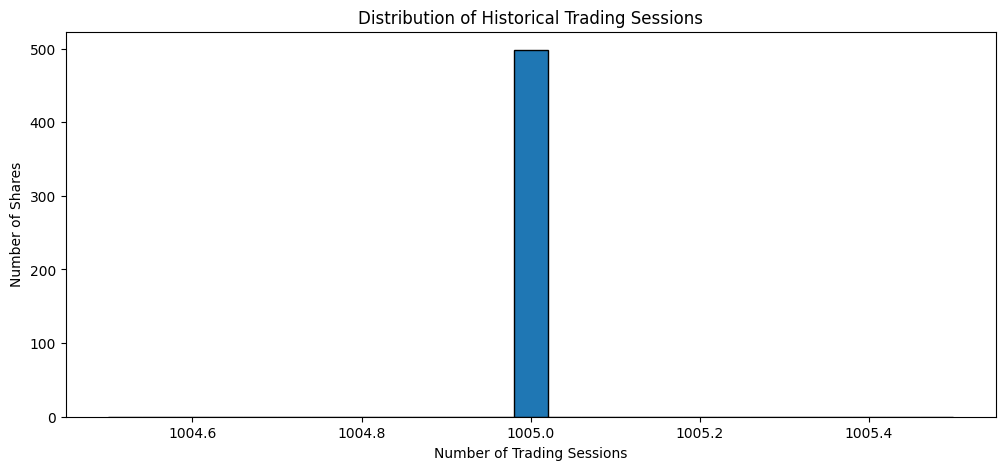

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.hist(
    history_summary["Trading_Sessions"],
    bins=25,
    edgecolor="black")

plt.title("Distribution of Historical Trading Sessions")
plt.xlabel("Number of Trading Sessions")
plt.ylabel("Number of Shares")

plt.show()

In [19]:
# Check whether corporate action columns exist
print("Available columns:")
print(all_stocks.columns.tolist())

# Count stock splits and dividends
if "Stock Splits" in all_stocks.columns:

    stock_splits = all_stocks[
        all_stocks["Stock Splits"].fillna(0) != 0]

    print("\nStock split events:",
          len(stock_splits))

    display(
        stock_splits[
            ["Ticker", "Date", "Stock Splits"]
        ].head(20))

if "Dividends" in all_stocks.columns:

    dividend_events = all_stocks[
        all_stocks["Dividends"].fillna(0) != 0]

    print("\nDividend events:",
          len(dividend_events))

    display(
        dividend_events[
            ["Ticker", "Date", "Dividends"]
        ].head(20))

Available columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits', 'Ticker']

Stock split events: 61


Price,Ticker,Date,Stock Splits
814,MMM,2024-04-01,1.196
19481,GOOGL,2022-07-18,20.000
20486,GOOG,2022-07-18,20.000
22468,AMZN,2022-06-06,20.000
33207,APH,2021-03-05,2.000
34030,APH,2024-06-12,2.000
45447,ANET,2021-11-18,4.000
46211,ANET,2024-12-04,4.000
48560,T,2022-04-11,1.324
59609,BDX,2022-04-01,1.025



Dividend events: 6086


Price,Ticker,Date,Dividends
27,MMM,2021-02-11,1.237458
95,MMM,2021-05-20,1.237458
159,MMM,2021-08-20,1.237458
222,MMM,2021-11-18,1.237458
284,MMM,2022-02-17,1.245819
347,MMM,2022-05-19,1.245819
410,MMM,2022-08-19,1.245819
473,MMM,2022-11-17,1.245819
534,MMM,2023-02-16,1.254181
597,MMM,2023-05-18,1.254181


In [20]:
# Standardise benchmark column names if they are MultiIndex
if isinstance(benchmark.columns, pd.MultiIndex):
    benchmark.columns = [
        col[0] for col in benchmark.columns]

print(benchmark.columns.tolist())

['Date', 'Adj Close', 'Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']


In [21]:
# Set Date as index
benchmark_weekly = (
    benchmark
    .set_index("Date")["Adj Close"]
    .resample("W-FRI")
    .last())

# Remove incomplete first and final calendar weeks
benchmark_weekly = benchmark_weekly.loc[
    "2021-01-08":"2024-12-27"]

print("Benchmark weekly observations:",
      benchmark_weekly.notna().sum())

display(benchmark_weekly.head())

Benchmark weekly observations: 208


,Adj Close
Date,
2021-01-08,3824.679932
2021-01-15,3768.250000
2021-01-22,3841.469971
2021-01-29,3714.239990
2021-02-05,3886.830078


In [22]:
weekly_stock_prices = (
    all_stocks
    .pivot_table(
        index="Date",
        columns="Ticker",
        values="Adj Close",
        aggfunc="last"
    )
    .resample("W-FRI")
    .last())

# Remove incomplete first and final calendar weeks
weekly_stock_prices = weekly_stock_prices.loc[
    "2021-01-08":"2024-12-27"]

print("Weekly stock dataset shape:",
      weekly_stock_prices.shape)

display(weekly_stock_prices.head())

Weekly stock dataset shape: (208, 498)


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,122.100441,128.098083,85.705215,149.770004,99.498405,34.650742,238.995865,485.100006,142.359055,44.473663,...,26.578348,104.901443,54.840767,36.195759,100.191040,241.449997,96.210388,146.956482,405.470001,157.178131
2021-01-15,121.283623,123.335045,89.334625,169.270004,99.621773,32.986668,230.271225,458.079987,143.276367,44.160637,...,25.893587,102.207481,54.173611,38.130558,96.570824,227.750000,95.734512,148.038208,409.220001,151.054001
2021-01-22,121.398956,134.908035,89.609467,181.869995,101.000183,31.674431,231.288010,472.440002,141.305481,44.685146,...,26.442986,103.381264,54.006817,37.764301,95.731071,222.880005,96.156532,148.861053,408.839996,152.945587
2021-01-29,115.479393,128.010803,82.835815,183.630005,110.622223,29.867723,219.622375,458.769989,133.812439,42.307938,...,24.834593,95.761177,53.364685,35.702106,90.123436,215.960007,91.128242,142.074860,387.829987,144.442902
2021-02-05,118.371910,132.865387,87.887756,195.309998,111.016068,32.140369,230.171371,492.119995,135.111191,45.091225,...,27.390514,112.560028,52.906002,39.770744,91.616318,240.380005,94.585197,147.825592,407.109985,149.153107


In [23]:
# Calculate weekly returns without filling missing prices
stock_weekly_returns = weekly_stock_prices.pct_change(
    fill_method=None)

benchmark_weekly_returns = benchmark_weekly.pct_change(
    fill_method=None)

# Check each share against the benchmark
alignment_results = []

for ticker in weekly_stock_prices.columns:
    aligned = pd.concat(
        [
            stock_weekly_returns[ticker].rename("Stock_Return"),
            benchmark_weekly_returns.rename("Market_Return")
        ],
        axis=1,
        join="inner"
    ).dropna()

    alignment_results.append({
        "Ticker": ticker,
        "Aligned_Weekly_Observations": len(aligned),
        "First_Aligned_Week": (
            aligned.index.min() if not aligned.empty else None
        ),
        "Last_Aligned_Week": (
            aligned.index.max() if not aligned.empty else None)})

alignment_summary = pd.DataFrame(alignment_results)
display(alignment_summary.head(20))

print(
    "Shares with aligned weekly observations:",
    (alignment_summary["Aligned_Weekly_Observations"] > 0).sum())

,Ticker,Aligned_Weekly_Observations,First_Aligned_Week,Last_Aligned_Week
0,A,207,2021-01-15,2024-12-27
1,AAPL,207,2021-01-15,2024-12-27
2,ABBV,207,2021-01-15,2024-12-27
3,ABNB,207,2021-01-15,2024-12-27
4,ABT,207,2021-01-15,2024-12-27
5,ACGL,207,2021-01-15,2024-12-27
6,ACN,207,2021-01-15,2024-12-27
7,ADBE,207,2021-01-15,2024-12-27
8,ADI,207,2021-01-15,2024-12-27
9,ADM,207,2021-01-15,2024-12-27


Shares with aligned weekly observations: 498


In [24]:
# Identify shares with invalid price or volume records
invalid_price_tickers = set(
    invalid_prices["Ticker"].unique())

invalid_volume_tickers = set(
    negative_volume["Ticker"].unique())

missing_price_tickers = set(
    all_stocks.loc[
        all_stocks[price_columns].isnull().any(axis=1),
        "Ticker"
    ].unique())

missing_volume_tickers = set(
    missing_volume["Ticker"].unique())

duplicate_tickers = set(
    duplicate_stocks["Ticker"].unique())

# Build preliminary validation summary
validation_summary = history_summary.copy()

validation_summary["Duplicate_Records"] = (
    validation_summary["Ticker"].isin(duplicate_tickers))

validation_summary["Invalid_Prices"] = (
    validation_summary["Ticker"].isin(invalid_price_tickers))

validation_summary["Invalid_Volume"] = (
    validation_summary["Ticker"].isin(invalid_volume_tickers))

validation_summary["Missing_Prices"] = (
    validation_summary["Ticker"].isin(missing_price_tickers))

validation_summary["Missing_Volume"] = (
    validation_summary["Ticker"].isin(missing_volume_tickers))

validation_summary["Aligned_Weeks"] = (
    validation_summary["Ticker"].map(
        alignment_summary.set_index("Ticker")[
            "Aligned_Weekly_Observations"]))

display(validation_summary.head(20))

validation_summary.to_csv(
    "validation_summary.csv",
    index=False)

,Ticker,First_Date,Last_Date,Trading_Sessions,Missing_Adj_Close,Missing_Volume,Duplicate_Records,Invalid_Prices,Invalid_Volume,Missing_Prices,Aligned_Weeks
0,A,2021-01-04,2024-12-31,1005,0,False,False,False,False,False,207
1,AAPL,2021-01-04,2024-12-31,1005,0,False,False,False,False,False,207
2,ABBV,2021-01-04,2024-12-31,1005,0,False,False,False,False,False,207
3,ABNB,2021-01-04,2024-12-31,1005,0,False,False,False,False,False,207
4,ABT,2021-01-04,2024-12-31,1005,0,False,False,False,False,False,207
5,ACGL,2021-01-04,2024-12-31,1005,0,False,False,False,False,False,207
6,ACN,2021-01-04,2024-12-31,1005,0,False,False,False,False,False,207
7,ADBE,2021-01-04,2024-12-31,1005,0,False,False,False,False,False,207
8,ADI,2021-01-04,2024-12-31,1005,0,False,False,False,False,False,207
9,ADM,2021-01-04,2024-12-31,1005,0,False,False,False,False,False,207


In [25]:
# Question 1.3

In [26]:
print("Weekly stock prices:")
display(weekly_stock_prices.head())

print("Weekly benchmark prices:")
display(benchmark_weekly.head())

print("Stock price shape:", weekly_stock_prices.shape)
print("Benchmark price count:", len(benchmark_weekly))

Weekly stock prices:


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,122.100441,128.098083,85.705215,149.770004,99.498405,34.650742,238.995865,485.100006,142.359055,44.473663,...,26.578348,104.901443,54.840767,36.195759,100.191040,241.449997,96.210388,146.956482,405.470001,157.178131
2021-01-15,121.283623,123.335045,89.334625,169.270004,99.621773,32.986668,230.271225,458.079987,143.276367,44.160637,...,25.893587,102.207481,54.173611,38.130558,96.570824,227.750000,95.734512,148.038208,409.220001,151.054001
2021-01-22,121.398956,134.908035,89.609467,181.869995,101.000183,31.674431,231.288010,472.440002,141.305481,44.685146,...,26.442986,103.381264,54.006817,37.764301,95.731071,222.880005,96.156532,148.861053,408.839996,152.945587
2021-01-29,115.479393,128.010803,82.835815,183.630005,110.622223,29.867723,219.622375,458.769989,133.812439,42.307938,...,24.834593,95.761177,53.364685,35.702106,90.123436,215.960007,91.128242,142.074860,387.829987,144.442902
2021-02-05,118.371910,132.865387,87.887756,195.309998,111.016068,32.140369,230.171371,492.119995,135.111191,45.091225,...,27.390514,112.560028,52.906002,39.770744,91.616318,240.380005,94.585197,147.825592,407.109985,149.153107


Weekly benchmark prices:


,Adj Close
Date,
2021-01-08,3824.679932
2021-01-15,3768.250000
2021-01-22,3841.469971
2021-01-29,3714.239990
2021-02-05,3886.830078


Stock price shape: (208, 498)
Benchmark price count: 208


In [27]:
# Calculate weekly returns for each stock
stock_weekly_returns = weekly_stock_prices.pct_change(fill_method=None)
benchmark_weekly_returns = benchmark_weekly.pct_change(fill_method=None)

print("Stock weekly returns:")
display(stock_weekly_returns.head())

print("S&P 500 weekly returns:")
display(benchmark_weekly_returns.head())

Stock weekly returns:


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-15,-0.006690,-0.037183,0.042348,0.130200,0.001240,-0.048024,-0.036505,-0.055700,0.006444,-0.007038,...,-0.025764,-0.025681,-0.012165,0.053454,-0.036133,-0.056741,-0.004946,0.007361,0.009249,-0.038963
2021-01-22,0.000951,0.093834,0.003077,0.074437,0.013836,-0.039781,0.004416,0.031348,-0.013756,0.011877,...,0.021218,0.011484,-0.003079,-0.009605,-0.008696,-0.021383,0.004408,0.005558,-0.000929,0.012523
2021-01-29,-0.048761,-0.051125,-0.075591,0.009677,0.095268,-0.057040,-0.050438,-0.028935,-0.053027,-0.053199,...,-0.060825,-0.073709,-0.011890,-0.054607,-0.058577,-0.031048,-0.052293,-0.045587,-0.051389,-0.055593
2021-02-05,0.025048,0.037923,0.060987,0.063606,0.003560,0.076090,0.048032,0.072694,0.009706,0.065786,...,0.102918,0.175424,-0.008595,0.113961,0.016565,0.113076,0.037935,0.040477,0.049713,0.032609


S&P 500 weekly returns:


,Adj Close
Date,
2021-01-08,NaN
2021-01-15,-0.014754
2021-01-22,0.019431
2021-01-29,-0.033120
2021-02-05,0.046467


In [28]:
results = []
for ticker in stock_weekly_returns.columns:
    # Align the stock and market returns using the same weekly dates
    aligned = pd.concat([stock_weekly_returns[ticker].rename("Stock_Return"),
            benchmark_weekly_returns.rename("Market_Return")], axis=1, join="inner").dropna()

    # Calculate only when sufficient observations are available
    if len(aligned) >= 2 and aligned["Market_Return"].var() != 0:
        mean_weekly_return = aligned["Stock_Return"].mean()
        beta = (
            aligned["Stock_Return"].cov(aligned["Market_Return"])
            / aligned["Market_Return"].var())

        results.append({
            "Ticker": ticker,
            "Mean_Weekly_Return": mean_weekly_return,
            "Mean_Weekly_Return_%": mean_weekly_return * 100,
            "Beta": beta,
            "Weekly_Observations": len(aligned)})

# Create the final results table
weekly_return_beta = pd.DataFrame(results)
display(weekly_return_beta.head(10))

print("Total shares calculated:", len(weekly_return_beta))

,Ticker,Mean_Weekly_Return,Mean_Weekly_Return_%,Beta,Weekly_Observations
0,A,0.001121,0.112061,1.074724,207
1,AAPL,0.003930,0.392980,1.174836,207
2,ABBV,0.003749,0.374916,0.425366,207
3,ABNB,0.001475,0.147547,1.472709,207
4,ABT,0.000971,0.097133,0.583543,207
5,ACGL,0.005289,0.528878,0.586638,207
6,ACN,0.002376,0.237638,1.143301,207
7,ADBE,0.000990,0.099002,1.553525,207
8,ADI,0.002610,0.261014,1.131968,207
9,ADM,0.001048,0.104759,0.548876,207


Total shares calculated: 498


In [29]:
print("Missing values:")
display(weekly_return_beta.isnull().sum())

print("Summary statistics:")
display(weekly_return_beta[["Mean_Weekly_Return_%", "Beta"]].describe())

# Save the results
weekly_return_beta.to_csv(
    "weekly_returns_and_beta.csv",
    index=False)

Missing values:


,0
Ticker,0
Mean_Weekly_Return,0
Mean_Weekly_Return_%,0
Beta,0
Weekly_Observations,0


Summary statistics:


,Mean_Weekly_Return_%,Beta
count,498.000000,498.000000
mean,0.303484,0.984162
std,0.330440,0.427134
min,-0.446809,0.055453
25%,0.121606,0.671472
50%,0.268899,0.954712
75%,0.432060,1.188554
max,3.849094,3.778560


In [30]:
# Question 1.4

In [31]:
# Identify the latest available date for each stock
stock_latest_dates = all_stocks.groupby("Ticker")["Date"].max()

# Find the latest available benchmark date
benchmark_latest_date = benchmark["Date"].max()

# Identifying the final common date across all stocks and the benchmark
observation_date = min(
    stock_latest_dates.min(),
    benchmark_latest_date)

print("Observation date:", observation_date)

Observation date: 2024-12-31 00:00:00


In [32]:
# This is to make sure dates use the same format
all_stocks["Date"] = pd.to_datetime(all_stocks["Date"])
benchmark["Date"] = pd.to_datetime(benchmark["Date"])

# Find dates available for every stock
common_dates = None
for ticker, group in all_stocks.groupby("Ticker"):
    ticker_dates = set(group["Date"].dropna())

    if common_dates is None:
        common_dates = ticker_dates
    else:
        common_dates = common_dates.intersection(ticker_dates)

# Also require the date to be available for the S&P 500
benchmark_dates = set(benchmark["Date"].dropna())
common_dates = common_dates.intersection(benchmark_dates)

# Latest date common to all stocks and the benchmark
observation_date = max(common_dates)

print("Final common observation date:", observation_date)
print("Number of shares included:", all_stocks["Ticker"].nunique())

Final common observation date: 2024-12-31 00:00:00
Number of shares included: 498


In [33]:
# Keep the data up to the observation date
rfm_data = all_stocks[all_stocks["Date"] <= observation_date].copy()

# Sort by ticker and date
rfm_data = rfm_data.sort_values(by=["Ticker", "Date"]).reset_index(drop=True)

print("Prepared dataset:")
display(rfm_data.head())

print("Latest date in dataset:", rfm_data["Date"].max())

Prepared dataset:


Price,Date,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Ticker
0,2021-01-04,118.940002,120.089996,117.110001,118.639999,114.009125,2030700.0,0.194,0.0,A
1,2021-01-05,118.480003,120.320000,118.070000,119.610001,114.941254,2344000.0,0.000,0.0,A
2,2021-01-06,118.690002,123.879997,118.209999,122.889999,118.093224,2428500.0,0.000,0.0,A
3,2021-01-07,124.330002,127.480003,124.110001,126.160004,121.235619,1775900.0,0.000,0.0,A
4,2021-01-08,126.489998,127.639999,125.849998,127.059998,122.100441,1577200.0,0.000,0.0,A


Latest date in dataset: 2024-12-31 00:00:00


In [34]:
# For calculating the average volume of the previous 20 sessions
rfm_data["Previous_20_Day_Avg_Volume"] = (
    rfm_data.groupby("Ticker")["Volume"]
    .transform(lambda x: x.shift(1).rolling(window=20, min_periods=20).mean()))

# Identify high-volume events
rfm_data["High_Volume_Event"] = (
    rfm_data["Volume"] >
    2 * rfm_data["Previous_20_Day_Avg_Volume"])

display(
    rfm_data[["Ticker", "Date", "Volume", "Previous_20_Day_Avg_Volume", "High_Volume_Event"]].head(30))

Price,Ticker,Date,Volume,Previous_20_Day_Avg_Volume,High_Volume_Event
0,A,2021-01-04,2030700.0,NaN,False
1,A,2021-01-05,2344000.0,NaN,False
2,A,2021-01-06,2428500.0,NaN,False
3,A,2021-01-07,1775900.0,NaN,False
4,A,2021-01-08,1577200.0,NaN,False
5,A,2021-01-11,1746800.0,NaN,False
6,A,2021-01-12,1826400.0,NaN,False
7,A,2021-01-13,1530400.0,NaN,False
8,A,2021-01-14,924900.0,NaN,False
9,A,2021-01-15,2115400.0,NaN,False


In [35]:
rfm_results = []
for ticker, group in rfm_data.groupby("Ticker"):
    # Sort each share's daily data
    group = group.sort_values("Date").copy()

    # Select the latest 60 trading sessions
    latest_60 = group.tail(60)

    # Check whether 60 sessions are available
    if len(latest_60) < 60:
        rfm_results.append({
            "Ticker": ticker,
            "Recency": np.nan,
            "Frequency": np.nan,
            "Monetary": np.nan,
            "Trading_Sessions": len(latest_60),
            "Status": "Insufficient history"})
        continue

    # Check for missing or invalid values in the latest 60 sessions
    if (latest_60[["Close", "Volume"]].isnull().any().any() or (latest_60["Close"] <= 0).any() or (latest_60["Volume"] < 0).any()):
        rfm_results.append({
            "Ticker": ticker,
            "Recency": np.nan,
            "Frequency": np.nan,
            "Monetary": np.nan,
            "Trading_Sessions": len(latest_60),
            "Status": "Data quality issue"})
        continue

    events = latest_60[latest_60["High_Volume_Event"] == True]

    frequency = len(events)

    if frequency > 0:
        most_recent_event = events["Date"].max()
        recency = (observation_date - most_recent_event).days
    else:
        recency = np.nan

    # Monetary: approximate traded value over the latest 60 sessions
    monetary = (latest_60["Close"] * latest_60["Volume"]).sum()

    rfm_results.append({
        "Ticker": ticker,
        "Recency": recency,
        "Frequency": frequency,
        "Monetary": monetary,
        "Trading_Sessions": len(latest_60),
        "Status": "Included"})

rfm_df = pd.DataFrame(rfm_results)

display(rfm_df.head(10))

,Ticker,Recency,Frequency,Monetary,Trading_Sessions,Status
0,A,11.0,2,1.400180e+10,60,Included
1,AAPL,11.0,2,6.233034e+11,60,Included
2,ABBV,11.0,3,6.837054e+10,60,Included
3,ABNB,11.0,3,3.652850e+10,60,Included
4,ABT,11.0,1,3.523027e+10,60,Included
5,ACGL,11.0,4,1.196213e+10,60,Included
6,ACN,11.0,2,5.199430e+10,60,Included
7,ADBE,18.0,3,1.030403e+11,60,Included
8,ADI,36.0,1,3.849918e+10,60,Included
9,ADM,11.0,3,9.529780e+09,60,Included


In [36]:
# Check the RFM dataset
print("RFM dataset shape:", rfm_df.shape)

print("\nMissing values:")
display(rfm_df.isnull().sum())

print("\nShare inclusion status:")
display(rfm_df["Status"].value_counts())

print("\nRFM summary statistics:")
display(rfm_df[["Recency", "Frequency", "Monetary"]].describe())

# Save the RFM results
rfm_df.to_csv("stock_RFM_results.csv", index=False)

# Save the high-volume event data
rfm_data.to_csv("stock_high_volume_events.csv", index=False)

RFM dataset shape: (498, 6)

Missing values:


,0
Ticker,0
Recency,10
Frequency,0
Monetary,0
Trading_Sessions,0
Status,0



Share inclusion status:


,count
Status,
Included,498



RFM summary statistics:


,Recency,Frequency,Monetary
count,488.000000,498.000000,4.980000e+02
mean,18.536885,3.004016,3.961352e+10
std,15.365321,1.327614,1.278859e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.025102e+10
50%,11.000000,3.000000,1.679667e+10
75%,13.000000,4.000000,3.287502e+10
max,85.000000,8.000000,1.847697e+12


In [37]:
# Compare the original ticker list with downloaded stock data
expected_tickers = set(sp500["Yahoo_Ticker"].unique())
downloaded_tickers = set(all_stocks["Ticker"].unique())

missing_tickers = expected_tickers - downloaded_tickers
extra_tickers = downloaded_tickers - expected_tickers

print("Expected tickers:", len(expected_tickers))
print("Downloaded tickers:", len(downloaded_tickers))

print("\nTickers not downloaded:")
print(sorted(missing_tickers))

print("\nUnexpected tickers:")
print(sorted(extra_tickers))

Expected tickers: 503
Downloaded tickers: 498

Tickers not downloaded:
['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']

Unexpected tickers:
[]


In [38]:
# Question 1.5

In [39]:
# Selecting Apple as the example
example_ticker = "AAPL"
example_data = rfm_data[rfm_data["Ticker"] == example_ticker].sort_values("Date").copy()

example_60 = example_data.tail(60)
example_events = example_60[
    example_60["High_Volume_Event"] == True]

# To calculate the three RFM measures
example_frequency = len(example_events)
if example_frequency > 0:
    example_recency = (observation_date - example_events["Date"].max()).days
else:
    example_recency = np.nan

example_monetary = (example_60["Close"] * example_60["Volume"]).sum()

print("Worked RFM Example:", example_ticker)
print("Observation date:", observation_date)
print("Trading sessions:", len(example_60))
print("Recency:", example_recency)
print("Frequency:", example_frequency)
print("Monetary: $", round(example_monetary, 2))

print("\nHigh-volume events:")
display(
    example_events[
        [
            "Date",
            "Volume",
            "Previous_20_Day_Avg_Volume",
            "High_Volume_Event"]])

Worked RFM Example: AAPL
Observation date: 2024-12-31 00:00:00
Trading sessions: 60
Recency: 11
Frequency: 2
Monetary: $ 623303377706.58

High-volume events:


Price,Date,Volume,Previous_20_Day_Avg_Volume,High_Volume_Event
1985,2024-11-25,90152800.0,43820740.0,True
2003,2024-12-20,147495300.0,45004605.0,True


In [40]:
if not example_events.empty:
    worked_event = example_events.iloc[0]
    threshold = (2 * worked_event["Previous_20_Day_Avg_Volume"])

    print("Date:", worked_event["Date"])
    print("Previous 20-session average volume:",
          worked_event["Previous_20_Day_Avg_Volume"])
    print("Event threshold:", threshold)
    print("Actual trading volume:", worked_event["Volume"])
    print(
        "Calculation:",
        worked_event["Volume"],
        ">",
        threshold
    )
else:
    print("No high-volume event found for AAPL.")

Date: 2024-11-25 00:00:00
Previous 20-session average volume: 43820740.0
Event threshold: 87641480.0
Actual trading volume: 90152800.0
Calculation: 90152800.0 > 87641480.0


In [41]:
rfm_feature_summary = rfm_df[
    ["Recency", "Frequency", "Monetary"]].describe().T

rfm_feature_summary = rfm_feature_summary[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]

display(rfm_feature_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
Recency,488.0,1.854000e+01,1.537000e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.300000e+01,8.500000e+01
Frequency,498.0,3.000000e+00,1.330000e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
Monetary,498.0,3.961352e+10,1.278859e+11,1.297483e+09,1.025102e+10,1.679667e+10,3.287502e+10,1.847697e+12


In [42]:
baseline_checks = []
for ticker, group in rfm_data.groupby("Ticker"):
    latest_60 = group.sort_values("Date").tail(60)
    baseline_checks.append({
        "Ticker": ticker,
        "Trading_Sessions": len(latest_60),
        "Valid_20_Session_Baselines":
            latest_60["Previous_20_Day_Avg_Volume"].notna().sum(),
        "Missing_Baselines":
            latest_60["Previous_20_Day_Avg_Volume"].isna().sum(),
        "Valid_Close":
            latest_60["Close"].notna().all(),
        "Valid_Volume":
            latest_60["Volume"].notna().all()})

baseline_validation = pd.DataFrame(baseline_checks)
display(baseline_validation.head(10))
print("\nTrading session check:")
print(baseline_validation["Trading_Sessions"].value_counts())
print("\nBaseline availability:")
print(
    baseline_validation[
        "Valid_20_Session_Baselines"
    ].value_counts())

print("\nShares with all 60 baselines available:",
      (baseline_validation["Valid_20_Session_Baselines"] == 60).sum())

,Ticker,Trading_Sessions,Valid_20_Session_Baselines,Missing_Baselines,Valid_Close,Valid_Volume
0,A,60,60,0,True,True
1,AAPL,60,60,0,True,True
2,ABBV,60,60,0,True,True
3,ABNB,60,60,0,True,True
4,ABT,60,60,0,True,True
5,ACGL,60,60,0,True,True
6,ACN,60,60,0,True,True
7,ADBE,60,60,0,True,True
8,ADI,60,60,0,True,True
9,ADM,60,60,0,True,True



Trading session check:
Trading_Sessions
60    498
Name: count, dtype: int64

Baseline availability:
Valid_20_Session_Baselines
60    498
Name: count, dtype: int64

Shares with all 60 baselines available: 498


In [43]:
# Create a record of downloaded and missing tickers
inclusion_exclusion_log = pd.DataFrame({
    "Ticker": sp500["Yahoo_Ticker"]})

downloaded_tickers = set(all_stocks["Ticker"].unique())
inclusion_exclusion_log["Download_Status"] = (
    inclusion_exclusion_log["Ticker"].apply(
        lambda x: "Downloaded" if x in downloaded_tickers
        else "Not downloaded"))

# Add RFM status
rfm_status = rfm_df.set_index("Ticker")["Status"].to_dict()

inclusion_exclusion_log["RFM_Status"] = (
    inclusion_exclusion_log["Ticker"].map(rfm_status))

inclusion_exclusion_log["RFM_Status"] = (
    inclusion_exclusion_log["RFM_Status"].fillna("Not calculated"))

# Add Recency availability
recency_status = rfm_df.set_index("Ticker")["Recency"].notna().to_dict()

inclusion_exclusion_log["Recency_Available"] = (
    inclusion_exclusion_log["Ticker"].map(recency_status))

inclusion_exclusion_log["Recency_Available"] = (
    inclusion_exclusion_log["Recency_Available"].fillna(False))

display(inclusion_exclusion_log.head(15))

print("\nDownload status:")
display(inclusion_exclusion_log["Download_Status"].value_counts())

print("\nRFM status:")
display(inclusion_exclusion_log["RFM_Status"].value_counts())

inclusion_exclusion_log.to_csv(
    "stock_inclusion_exclusion_log.csv",
    index=False)

/tmp/ipykernel_1550/136867972.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  inclusion_exclusion_log["Recency_Available"].fillna(False))


,Ticker,Download_Status,RFM_Status,Recency_Available
0,MMM,Downloaded,Included,True
1,AOS,Downloaded,Included,True
2,ABT,Downloaded,Included,True
3,ABBV,Downloaded,Included,True
4,ACN,Downloaded,Included,True
5,ADBE,Downloaded,Included,True
6,AMD,Downloaded,Included,True
7,AES,Downloaded,Included,True
8,AFL,Downloaded,Included,True
9,A,Downloaded,Included,True



Download status:


,count
Download_Status,
Downloaded,498
Not downloaded,5



RFM status:


,count
RFM_Status,
Included,498
Not calculated,5


In [44]:
# Keep shares with valid R, F and M values
valid_rfm = rfm_df.dropna(subset=["Recency", "Frequency", "Monetary"]).copy()

# Match them with the weekly return and Beta results
common_valid_shares = valid_rfm.merge(
    weekly_return_beta,
    on="Ticker",
    how="inner")

print("Valid RFM shares:", len(valid_rfm))
print("Common valid shares for comparison:",
      len(common_valid_shares))

display(common_valid_shares.head())

common_valid_shares.to_csv(
    "common_valid_shares.csv",
    index=False)

Valid RFM shares: 488
Common valid shares for comparison: 488


,Ticker,Recency,Frequency,Monetary,Trading_Sessions,Status,Mean_Weekly_Return,Mean_Weekly_Return_%,Beta,Weekly_Observations
0,A,11.0,2,1.400180e+10,60,Included,0.001121,0.112061,1.074724,207
1,AAPL,11.0,2,6.233034e+11,60,Included,0.003930,0.392980,1.174836,207
2,ABBV,11.0,3,6.837054e+10,60,Included,0.003749,0.374916,0.425366,207
3,ABNB,11.0,3,3.652850e+10,60,Included,0.001475,0.147547,1.472709,207
4,ABT,11.0,1,3.523027e+10,60,Included,0.000971,0.097133,0.583543,207


# Task 2 - Stock Segmentation and Sensitivity Analysis

Question 2.1

In [45]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [46]:
risk_return_data = common_valid_shares[
    ["Ticker", "Mean_Weekly_Return", "Beta"]].copy()

rfm_clustering_data = common_valid_shares[["Ticker", "Recency", "Frequency", "Monetary"]].copy()

print("Risk-return dataset:")
print(risk_return_data.shape)
display(risk_return_data.head())

print("\nRFM dataset:")
print(rfm_clustering_data.shape)
display(rfm_clustering_data.head())

Risk-return dataset:
(488, 3)


,Ticker,Mean_Weekly_Return,Beta
0,A,0.001121,1.074724
1,AAPL,0.003930,1.174836
2,ABBV,0.003749,0.425366
3,ABNB,0.001475,1.472709
4,ABT,0.000971,0.583543



RFM dataset:
(488, 4)


,Ticker,Recency,Frequency,Monetary
0,A,11.0,2,1.400180e+10
1,AAPL,11.0,2,6.233034e+11
2,ABBV,11.0,3,6.837054e+10
3,ABNB,11.0,3,3.652850e+10
4,ABT,11.0,1,3.523027e+10


In [47]:
print("Risk-return missing values:")
display(risk_return_data.isnull().sum())

print("\nRFM missing values:")
display(rfm_clustering_data.isnull().sum())

print("\nRisk-return data types:")
print(risk_return_data.dtypes)

print("\nRFM data types:")
print(rfm_clustering_data.dtypes)

Risk-return missing values:


,0
Ticker,0
Mean_Weekly_Return,0
Beta,0



RFM missing values:


,0
Ticker,0
Recency,0
Frequency,0
Monetary,0



Risk-return data types:
Ticker                 object
Mean_Weekly_Return    float64
Beta                  float64
dtype: object

RFM data types:
Ticker        object
Recency      float64
Frequency      int64
Monetary     float64
dtype: object


In [48]:
# Select numerical features
risk_features = ["Mean_Weekly_Return", "Beta"]

rfm_features = ["Recency", "Frequency", "Monetary"]

# Display descriptive statistics
print("Risk-return feature statistics:")
display(risk_return_data[risk_features].describe())

print("\nRFM feature statistics:")
display(rfm_clustering_data[rfm_features].describe())

Risk-return feature statistics:


,Mean_Weekly_Return,Beta
count,488.000000,488.000000
mean,0.003032,0.988746
std,0.003288,0.422781
min,-0.004468,0.055453
25%,0.001227,0.688941
50%,0.002689,0.958366
75%,0.004316,1.191703
max,0.038491,3.778560



RFM feature statistics:


,Recency,Frequency,Monetary
count,488.000000,488.000000,4.880000e+02
mean,18.536885,3.065574,3.633220e+10
std,15.365321,1.268722,1.006119e+11
min,4.000000,1.000000,1.297483e+09
25%,11.000000,2.000000,1.023194e+10
50%,11.000000,3.000000,1.662477e+10
75%,13.000000,4.000000,3.323074e+10
max,85.000000,8.000000,1.847697e+12


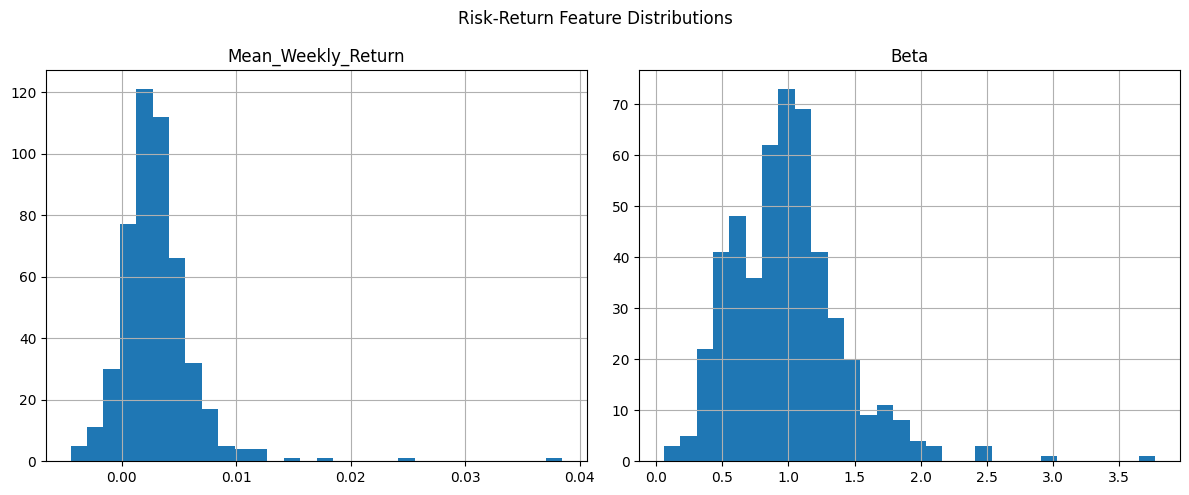

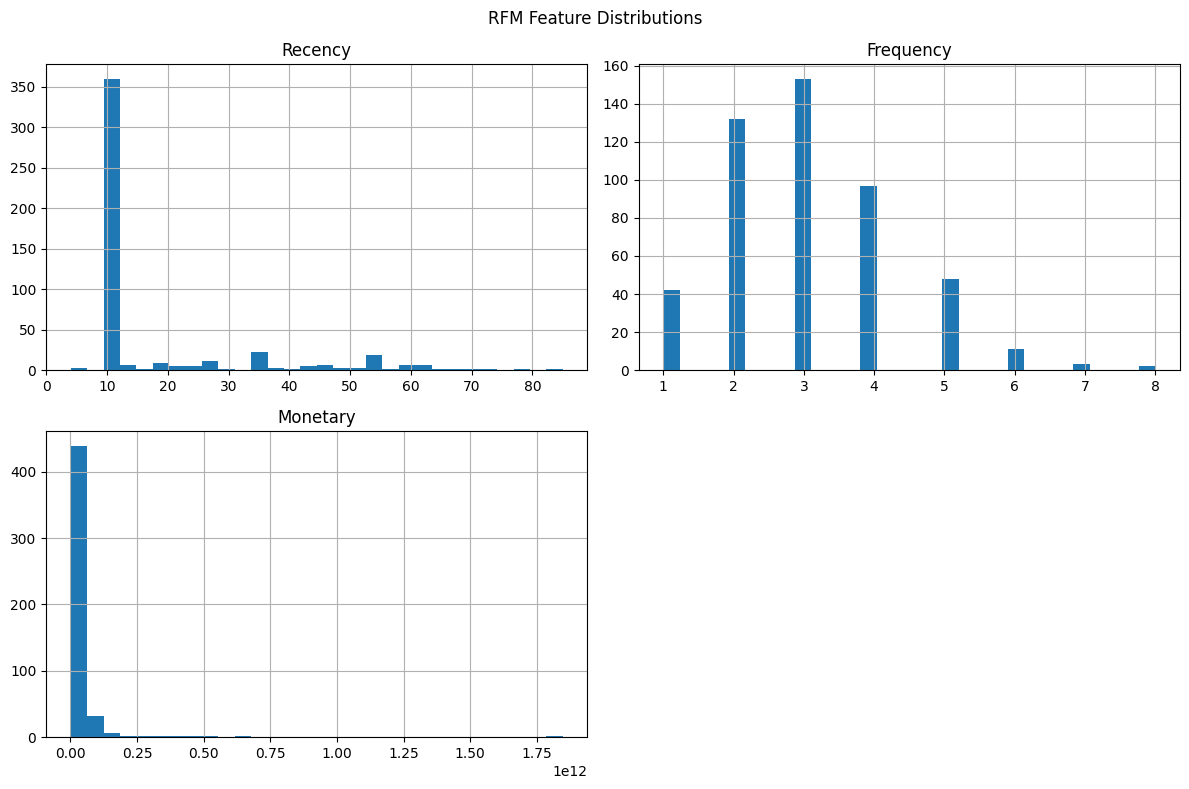

In [49]:
# Risk-return distributions
risk_return_data[risk_features].hist(
    figsize=(12, 5),
    bins=30)

plt.suptitle("Risk-Return Feature Distributions")
plt.tight_layout()
plt.show()

# RFM distributions
rfm_clustering_data[rfm_features].hist(
    figsize=(12, 8),
    bins=30)

plt.suptitle("RFM Feature Distributions")
plt.tight_layout()
plt.show()

In [50]:
# Calculate skewness for risk-return features
print("Risk-Return Skewness:")
display(risk_return_data[risk_features].skew().to_frame("Skewness"))

# Calculate skewness for RFM features
print("\nRFM Skewness:")
display(rfm_clustering_data[rfm_features].skew().to_frame("Skewness"))

Risk-Return Skewness:


,Skewness
Mean_Weekly_Return,3.626804
Beta,1.268665



RFM Skewness:


,Skewness
Recency,1.974123
Frequency,0.603399
Monetary,13.176208


In [51]:
def count_iqr_outliers(data, features):
    results = []
    for feature in features:

        Q1 = data[feature].quantile(0.25)
        Q3 = data[feature].quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = data[(data[feature] < lower_bound) | (data[feature] > upper_bound)]

        results.append({"Feature": feature, "Lower_Bound": lower_bound, "Upper_Bound": upper_bound, "Outlier_Count": len(outliers)})

    return pd.DataFrame(results)

print("Risk-Return Outliers:")
display(count_iqr_outliers(risk_return_data, risk_features))

print("\nRFM Outliers:")
display(count_iqr_outliers(rfm_clustering_data, rfm_features))

Risk-Return Outliers:


,Feature,Lower_Bound,Upper_Bound,Outlier_Count
0,Mean_Weekly_Return,-0.003408,0.008950,18
1,Beta,-0.065200,1.945844,12



RFM Outliers:


,Feature,Lower_Bound,Upper_Bound,Outlier_Count
0,Recency,8.000000e+00,1.600000e+01,120
1,Frequency,-1.000000e+00,7.000000e+00,2
2,Monetary,-2.426625e+10,6.772893e+10,45


In [52]:
# Create a copy of the RFM dataset
rfm_transformed = rfm_clustering_data.copy()

# Apply log1p transformation to Monetary
rfm_transformed["Log_Monetary"] = np.log1p(
    rfm_transformed["Monetary"])

print("Original Monetary:")
display(rfm_transformed["Monetary"].describe())

print("\nLog-transformed Monetary:")
display(rfm_transformed["Log_Monetary"].describe())

Original Monetary:


,Monetary
count,4.880000e+02
mean,3.633220e+10
std,1.006119e+11
min,1.297483e+09
25%,1.023194e+10
50%,1.662477e+10
75%,3.323074e+10
max,1.847697e+12



Log-transformed Monetary:


,Log_Monetary
count,488.000000
mean,23.684258
std,0.930348
min,20.983692
25%,23.048775
50%,23.534157
75%,24.226741
max,28.244961


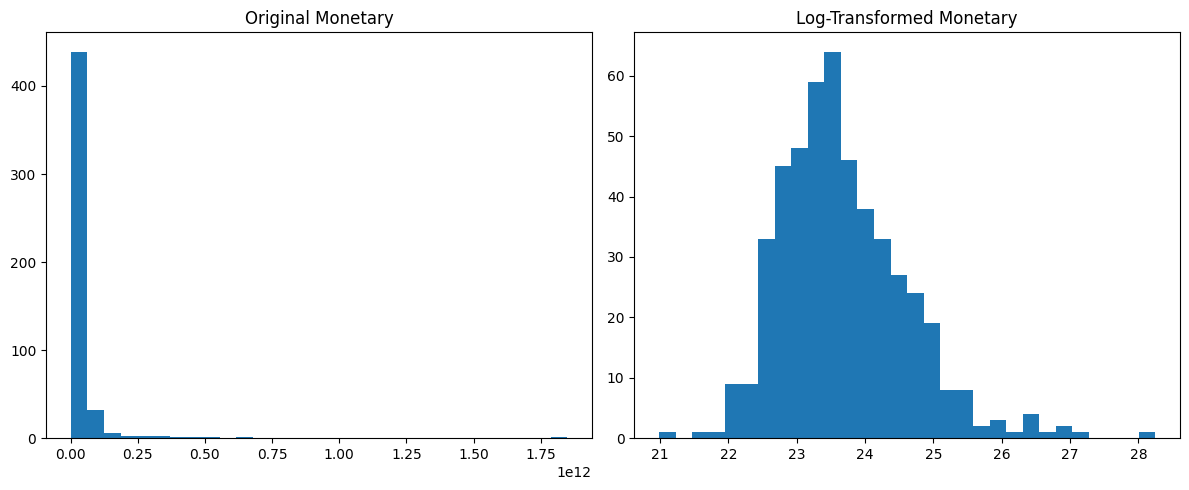

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(rfm_transformed["Monetary"], bins=30)
axes[0].set_title("Original Monetary")

axes[1].hist(rfm_transformed["Log_Monetary"], bins=30)
axes[1].set_title("Log-Transformed Monetary")

plt.tight_layout()
plt.show()

In [54]:
# Prepare risk-return features
X_risk = risk_return_data[risk_features].copy()

# Prepare transformed RFM features
X_rfm = rfm_transformed[
    ["Recency", "Frequency", "Log_Monetary"]].copy()

# Standardise risk-return features
risk_scaler = StandardScaler()

X_risk_scaled = risk_scaler.fit_transform(X_risk)

# Standardise RFM features
rfm_scaler = StandardScaler()

X_rfm_scaled = rfm_scaler.fit_transform(X_rfm)

print("Risk-return scaled shape:", X_risk_scaled.shape)
print("RFM scaled shape:", X_rfm_scaled.shape)

Risk-return scaled shape: (488, 2)
RFM scaled shape: (488, 3)


In [55]:
print("Risk-return standardised means:")
print(X_risk_scaled.mean(axis=0))

print("\nRisk-return standardised standard deviations:")
print(X_risk_scaled.std(axis=0))

print("\nRFM standardised means:")
print(X_rfm_scaled.mean(axis=0))

print("\nRFM standardised standard deviations:")
print(X_rfm_scaled.std(axis=0))

Risk-return standardised means:
[-4.73209814e-17 -2.02024190e-16]

Risk-return standardised standard deviations:
[1. 1.]

RFM standardised means:
[-3.64007549e-17 -4.00408304e-17  2.05300258e-15]

RFM standardised standard deviations:
[1. 1. 1.]


Question 2.2

In [56]:
print("Monetary skewness before:",
      rfm_clustering_data["Monetary"].skew())

print("Monetary skewness after:",
      rfm_transformed["Log_Monetary"].skew())

Monetary skewness before: 13.176207809940662
Monetary skewness after: 0.9207219069593814


In [57]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

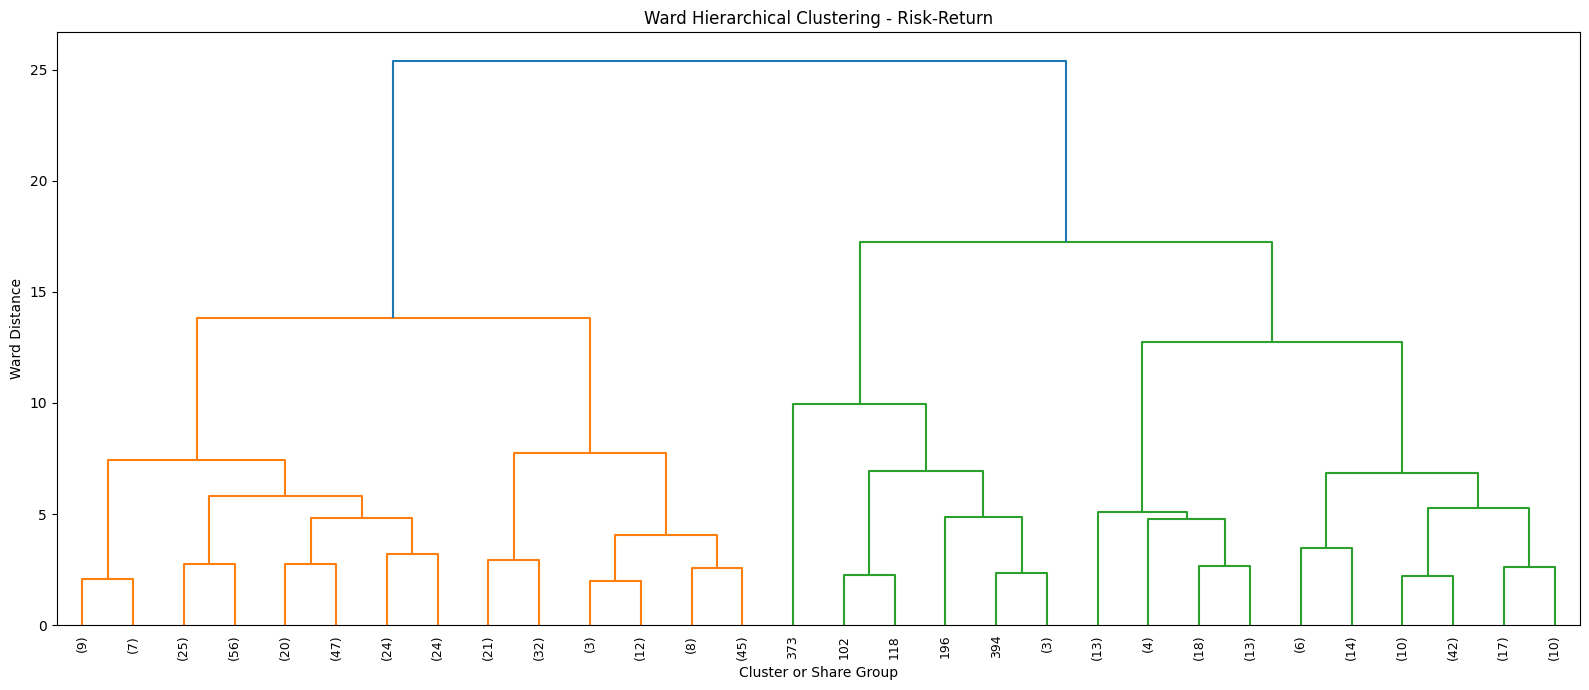

In [58]:
# Ward hierarchical clustering for Risk-Return
ward_risk_linkage = linkage(X_risk_scaled, method="ward", metric="euclidean")

# Plot dendrogram
plt.figure(figsize=(16, 7))
dendrogram(ward_risk_linkage, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9)

plt.title("Ward Hierarchical Clustering - Risk-Return")
plt.xlabel("Cluster or Share Group")
plt.ylabel("Ward Distance")

plt.tight_layout()
plt.show()

In [59]:
ward_risk_results = []
for k in range(2, 9):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward",
        metric="euclidean")

    labels = model.fit_predict(X_risk_scaled)
    score = silhouette_score(X_risk_scaled, labels)
    cluster_sizes = pd.Series(labels).value_counts()
    ward_risk_results.append({
        "Clusters": k,
        "Silhouette_Score": score,
        "Smallest_Cluster": cluster_sizes.min(),
        "Largest_Cluster": cluster_sizes.max()})

ward_risk_evaluation = pd.DataFrame(ward_risk_results)
display(ward_risk_evaluation)

,Clusters,Silhouette_Score,Smallest_Cluster,Largest_Cluster
0,2,0.390234,155,333
1,3,0.375746,8,333
2,4,0.308772,8,212
3,5,0.343927,8,212
4,6,0.345272,1,212
5,7,0.318787,1,212
6,8,0.322170,1,196


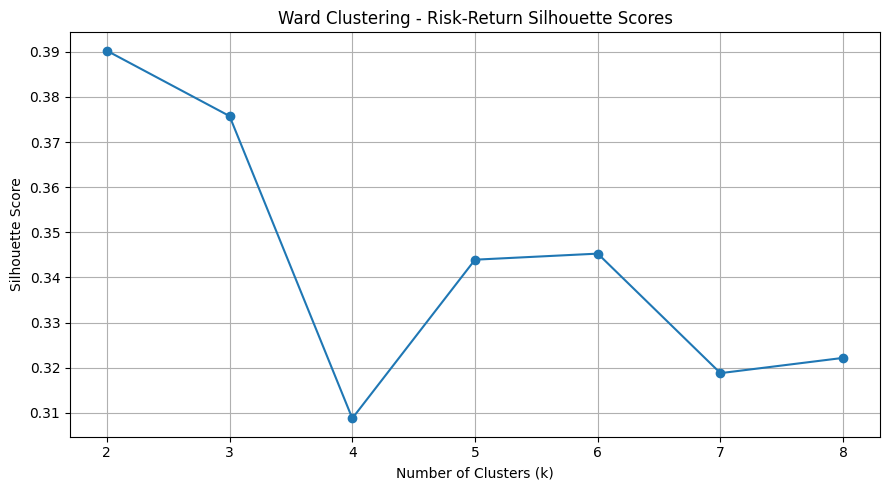

In [60]:
plt.figure(figsize=(9, 5))
plt.plot(
    ward_risk_evaluation["Clusters"],
    ward_risk_evaluation["Silhouette_Score"],
    marker="o")

plt.title("Ward Clustering - Risk-Return Silhouette Scores")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(True)
plt.tight_layout()
plt.show()

In [61]:
ward_risk_model = AgglomerativeClustering(n_clusters=2, linkage="ward", metric="euclidean")
risk_return_data["Ward_Risk_Cluster"] = ward_risk_model.fit_predict(X_risk_scaled)

print("Risk-Return Ward Cluster Sizes:")
print(risk_return_data["Ward_Risk_Cluster"].value_counts().sort_index())

Risk-Return Ward Cluster Sizes:
Ward_Risk_Cluster
0    155
1    333
Name: count, dtype: int64


In [62]:
ward_risk_profile = risk_return_data.groupby("Ward_Risk_Cluster").agg(
    Number_of_Shares=("Ticker", "count"),
    Average_Weekly_Return=("Mean_Weekly_Return", "mean"),
    Average_Beta=("Beta", "mean"),
    Minimum_Beta=("Beta", "min"),
    Maximum_Beta=("Beta", "max")).round(4)

display(ward_risk_profile)

,Number_of_Shares,Average_Weekly_Return,Average_Beta,Minimum_Beta,Maximum_Beta
Ward_Risk_Cluster,,,,,
0,155,0.0053,1.3960,0.5940,3.7786
1,333,0.0020,0.7992,0.0555,1.5558


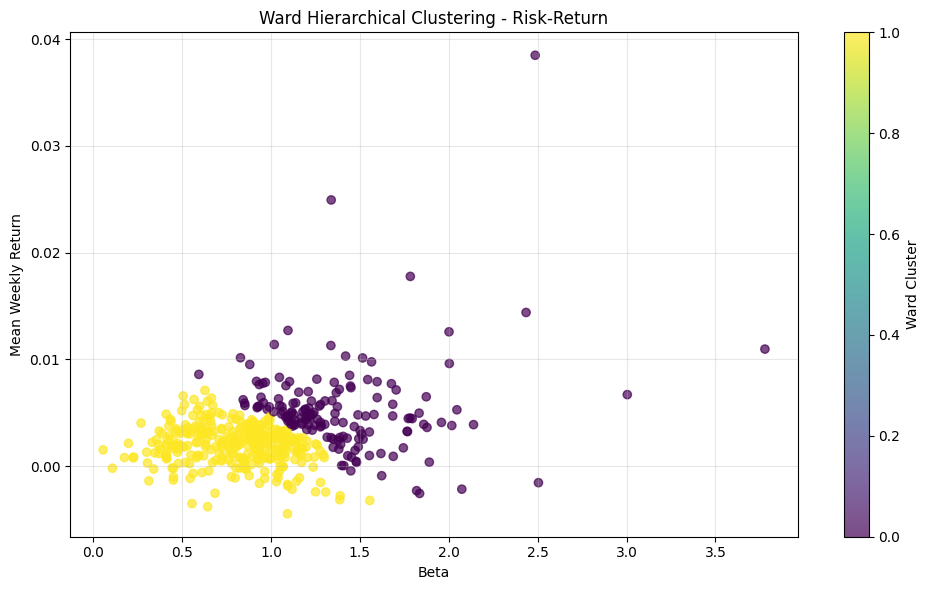

In [63]:
plt.figure(figsize=(10, 6))
plt.scatter(risk_return_data["Beta"], risk_return_data["Mean_Weekly_Return"], c=risk_return_data["Ward_Risk_Cluster"], cmap="viridis", alpha=0.7)

plt.title("Ward Hierarchical Clustering - Risk-Return")
plt.xlabel("Beta")
plt.ylabel("Mean Weekly Return")
plt.colorbar(label="Ward Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

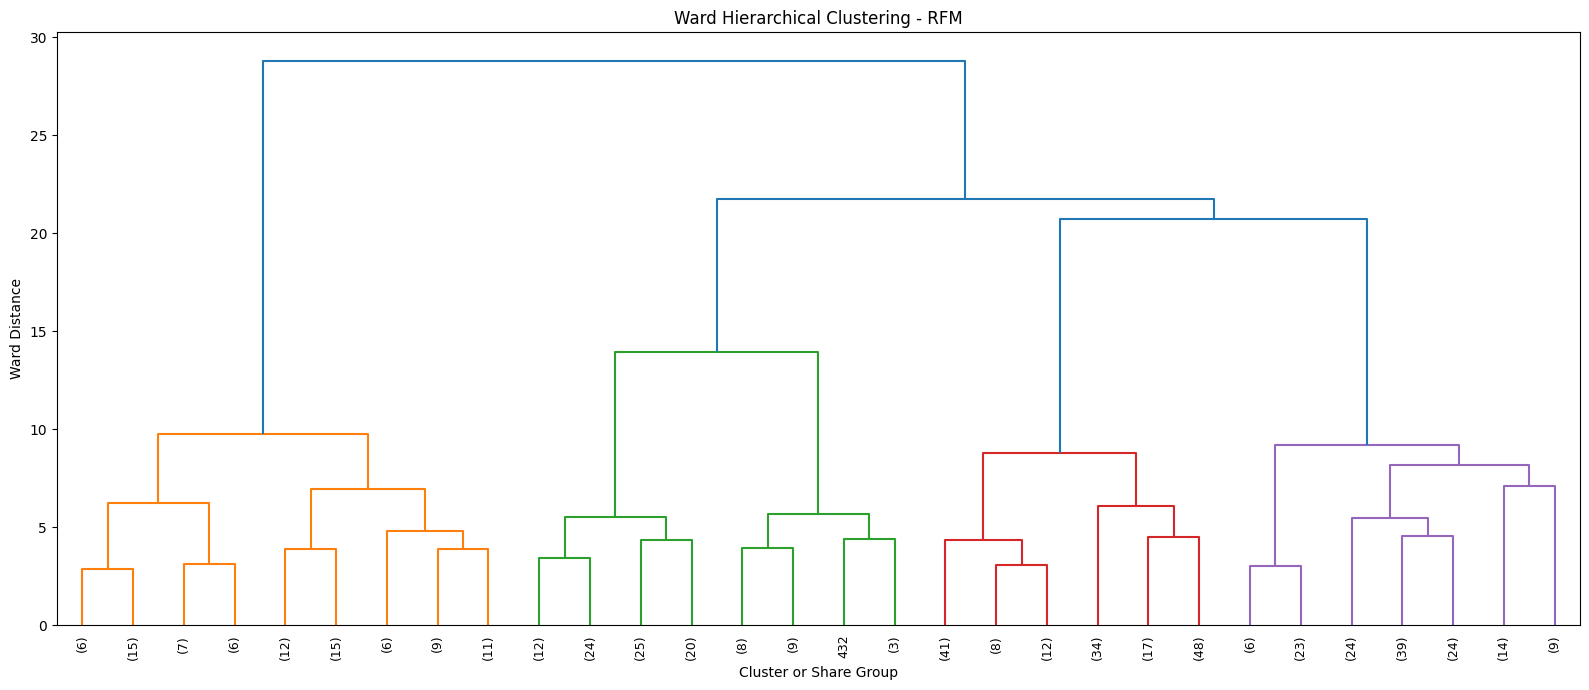

In [64]:
ward_rfm_linkage = linkage(X_rfm_scaled, method="ward", metric="euclidean")
plt.figure(figsize=(16, 7))
dendrogram(ward_rfm_linkage, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9)

plt.title("Ward Hierarchical Clustering - RFM")
plt.xlabel("Cluster or Share Group")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

In [65]:
ward_rfm_results = []
for k in range(2, 9):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward",
        metric="euclidean")

    labels = model.fit_predict(X_rfm_scaled)
    score = silhouette_score(X_rfm_scaled, labels)
    cluster_sizes = pd.Series(labels).value_counts()
    ward_rfm_results.append({
        "Clusters": k,
        "Silhouette_Score": score,
        "Smallest_Cluster": cluster_sizes.min(),
        "Largest_Cluster": cluster_sizes.max()})

ward_rfm_evaluation = pd.DataFrame(ward_rfm_results)
display(ward_rfm_evaluation)

,Clusters,Silhouette_Score,Smallest_Cluster,Largest_Cluster
0,2,0.387138,87,401
1,3,0.310581,87,299
2,4,0.326430,87,160
3,5,0.331974,21,160
4,6,0.316500,21,160
5,7,0.292308,21,160
6,8,0.269640,21,110


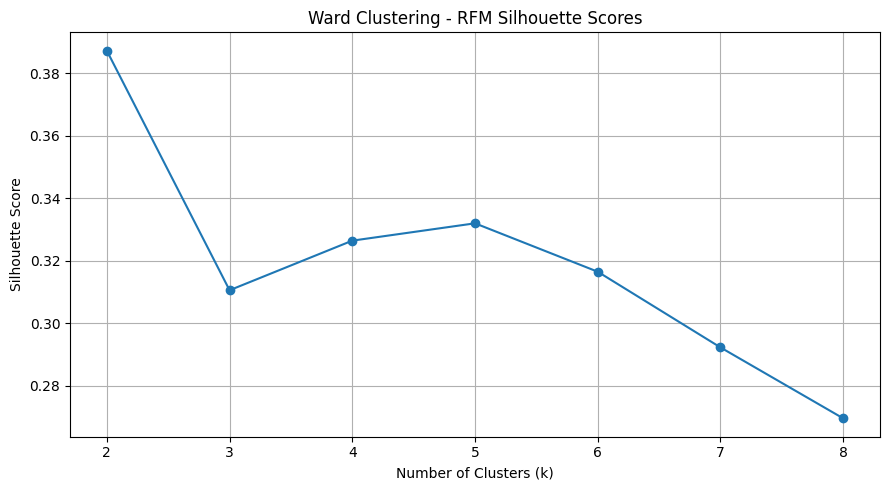

In [66]:
plt.figure(figsize=(9, 5))
plt.plot(
    ward_rfm_evaluation["Clusters"],
    ward_rfm_evaluation["Silhouette_Score"],
    marker="o")

plt.title("Ward Clustering - RFM Silhouette Scores")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(True)
plt.tight_layout()
plt.show()

In [67]:
ward_rfm_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward",
    metric="euclidean")

rfm_clustering_data["Ward_RFM_Cluster"] = ward_rfm_model.fit_predict(
    X_rfm_scaled)

print("RFM Ward Cluster Sizes:")
print(rfm_clustering_data["Ward_RFM_Cluster"].value_counts().sort_index())

RFM Ward Cluster Sizes:
Ward_RFM_Cluster
0    401
1     87
Name: count, dtype: int64


In [68]:
ward_rfm_profile = rfm_clustering_data.groupby(
    "Ward_RFM_Cluster").agg(
    Number_of_Shares=("Ticker", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")).round(2)

display(ward_rfm_profile)

,Number_of_Shares,Average_Recency,Average_Frequency,Average_Monetary
Ward_RFM_Cluster,,,,
0,401,12.28,3.23,3.757600e+10
1,87,47.38,2.32,3.059929e+10


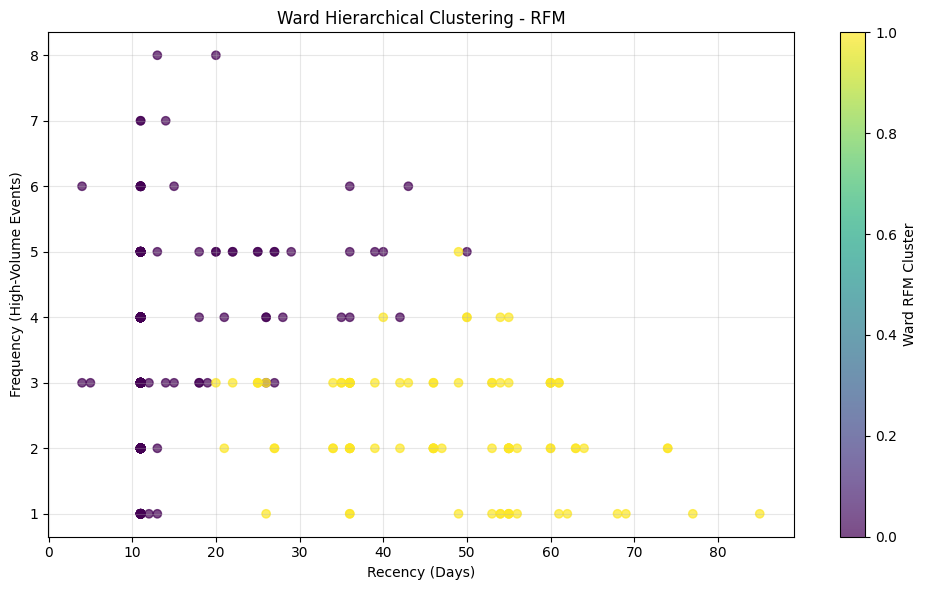

In [69]:
# Create a scatter plot to visualise the RFM clusters
plt.figure(figsize=(10, 6))
plt.scatter(
    rfm_clustering_data["Recency"],
    rfm_clustering_data["Frequency"],
    c=rfm_clustering_data["Ward_RFM_Cluster"],
    cmap="viridis",
    alpha=0.7)

# Add chart labels and title
plt.title("Ward Hierarchical Clustering - RFM")
plt.xlabel("Recency (Days)")
plt.ylabel("Frequency (High-Volume Events)")
plt.colorbar(label="Ward RFM Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Question 2.3

In [70]:
# Import K-Means clustering and evaluation metrics
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [71]:
# Store the evaluation results for each number of clusters
kmeans_risk_results = []
# Test cluster solutions from k=2 to k=8
for k in range(2, 9):
    # Create and fit the K-Means model
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10)

    labels = model.fit_predict(X_risk_scaled)
    # Calculate silhouette score and inertia
    silhouette = silhouette_score(X_risk_scaled, labels)
    inertia = model.inertia_

    # Calculate the smallest and largest cluster sizes
    cluster_sizes = pd.Series(labels).value_counts()

    # Save the evaluation results
    kmeans_risk_results.append({
        "Clusters": k,
        "Silhouette_Score": silhouette,
        "Inertia": inertia,
        "Smallest_Cluster": cluster_sizes.min(),
        "Largest_Cluster": cluster_sizes.max()})

# Display the evaluation results
kmeans_risk_evaluation = pd.DataFrame(kmeans_risk_results)
display(kmeans_risk_evaluation.round(4))

,Clusters,Silhouette_Score,Inertia,Smallest_Cluster,Largest_Cluster
0,2,0.3972,650.9464,145,343
1,3,0.3460,496.9799,8,275
2,4,0.3355,384.6819,7,184
3,5,0.3321,315.3245,3,157
4,6,0.3510,263.6440,2,181
5,7,0.3378,231.1438,1,151
6,8,0.3348,202.4450,2,147


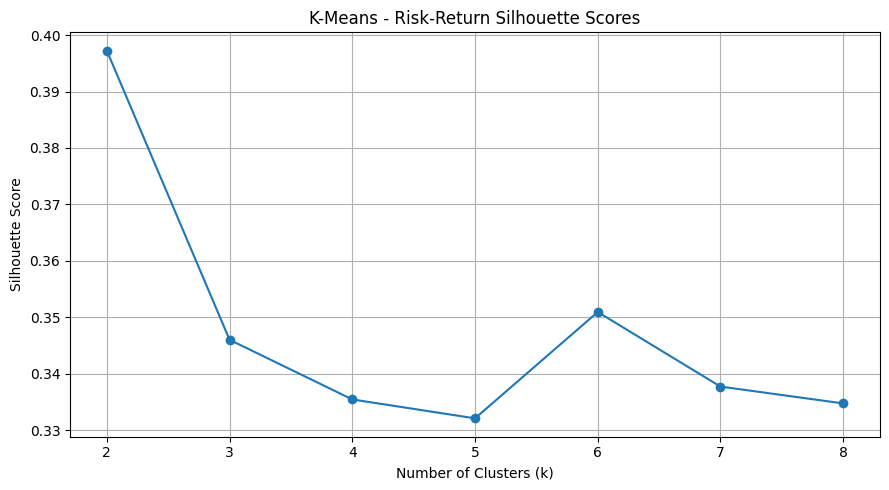

In [72]:
# Plot silhouette scores for different cluster numbers
plt.figure(figsize=(9, 5))

plt.plot(kmeans_risk_evaluation["Clusters"], kmeans_risk_evaluation["Silhouette_Score"], marker="o")

plt.title("K-Means - Risk-Return Silhouette Scores")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(True)
plt.tight_layout()
plt.show()

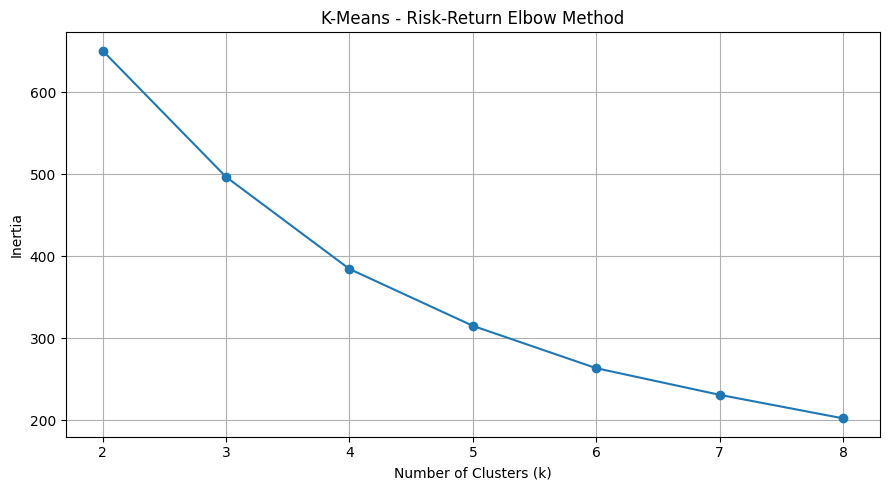

In [73]:
# Plot inertia to identify the elbow point
plt.figure(figsize=(9, 5))

plt.plot(kmeans_risk_evaluation["Clusters"], kmeans_risk_evaluation["Inertia"], marker="o")

plt.title("K-Means - Risk-Return Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(range(2, 9))
plt.grid(True)
plt.tight_layout()
plt.show()

In [74]:
# Create the final K-Means model with two clusters
kmeans_risk_model = KMeans(n_clusters=2, random_state=42, n_init=10)

# Assign each share to its K-Means cluster
risk_return_data["KMeans_Risk_Cluster"] = (
    kmeans_risk_model.fit_predict(X_risk_scaled))

# Display the number of shares in each cluster
print("Risk-Return K-Means Cluster Sizes:")
print(risk_return_data["KMeans_Risk_Cluster"].value_counts().sort_index())

Risk-Return K-Means Cluster Sizes:
KMeans_Risk_Cluster
0    343
1    145
Name: count, dtype: int64


In [75]:
# Calculate the original feature averages for each cluster
kmeans_risk_profile = risk_return_data.groupby(
    "KMeans_Risk_Cluster").agg(
    Number_of_Shares=("Ticker", "count"),
    Average_Weekly_Return=("Mean_Weekly_Return", "mean"),
    Average_Beta=("Beta", "mean"),
    Minimum_Beta=("Beta", "min"),
    Maximum_Beta=("Beta", "max")).round(4)

# Display the cluster profiles
display(kmeans_risk_profile)

,Number_of_Shares,Average_Weekly_Return,Average_Beta,Minimum_Beta,Maximum_Beta
KMeans_Risk_Cluster,,,,,
0,343,0.0020,0.8056,0.0555,1.5558
1,145,0.0054,1.4221,0.8282,3.7786


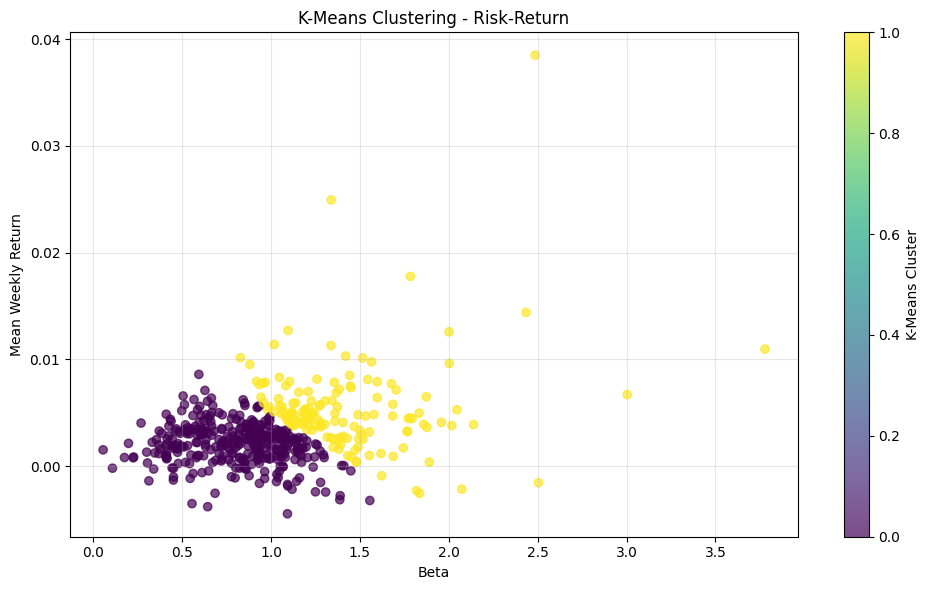

In [76]:
# Create a scatter plot of the K-Means clusters
plt.figure(figsize=(10, 6))
plt.scatter(
    risk_return_data["Beta"],
    risk_return_data["Mean_Weekly_Return"],
    c=risk_return_data["KMeans_Risk_Cluster"],
    cmap="viridis",
    alpha=0.7)

# Add chart title, axis labels and legend
plt.title("K-Means Clustering - Risk-Return")
plt.xlabel("Beta")
plt.ylabel("Mean Weekly Return")
plt.colorbar(label="K-Means Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [77]:
# Store RFM K-Means evaluation results
kmeans_rfm_results = []

# Test different numbers of clusters from 2 to 8
for k in range(2, 9):
# Create and fit the K-Means model
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10)

    labels = model.fit_predict(X_rfm_scaled)

    # Calculate silhouette score and inertia
    silhouette = silhouette_score(X_rfm_scaled, labels)
    inertia = model.inertia_

    # Check the smallest and largest cluster sizes
    cluster_sizes = pd.Series(labels).value_counts()

    # Save the evaluation results
    kmeans_rfm_results.append({
        "Clusters": k,
        "Silhouette_Score": silhouette,
        "Inertia": inertia,
        "Smallest_Cluster": cluster_sizes.min(),
        "Largest_Cluster": cluster_sizes.max()})

# Display the evaluation table
kmeans_rfm_evaluation = pd.DataFrame(kmeans_rfm_results)
display(kmeans_rfm_evaluation.round(4))

,Clusters,Silhouette_Score,Inertia,Smallest_Cluster,Largest_Cluster
0,2,0.4222,1024.7964,83,405
1,3,0.3388,753.7596,78,264
2,4,0.3649,545.9244,75,202
3,5,0.3516,459.1487,41,144
4,6,0.3376,412.2654,20,145
5,7,0.3235,374.1166,21,145
6,8,0.3130,335.1716,22,99


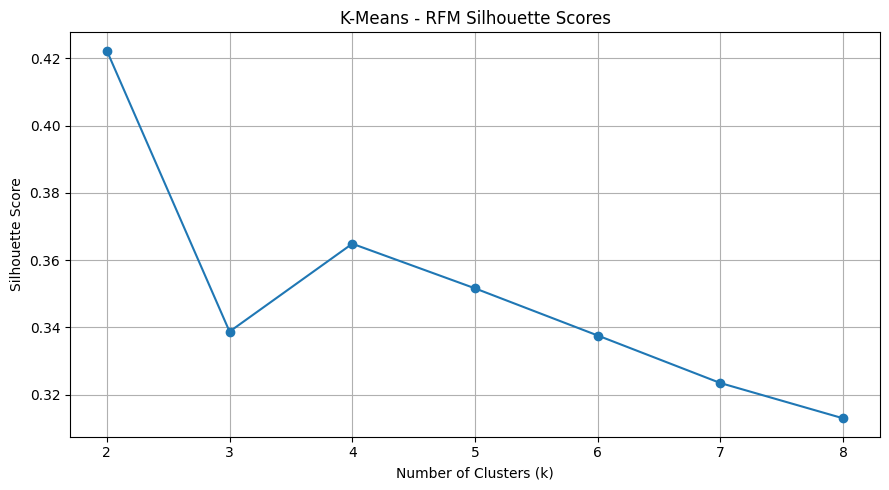

In [78]:
# Visualise silhouette scores for each cluster solution
plt.figure(figsize=(9, 5))

plt.plot(kmeans_rfm_evaluation["Clusters"], kmeans_rfm_evaluation["Silhouette_Score"], marker="o")

# Add chart labels and formatting
plt.title("K-Means - RFM Silhouette Scores")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(True)
plt.tight_layout()
plt.show()

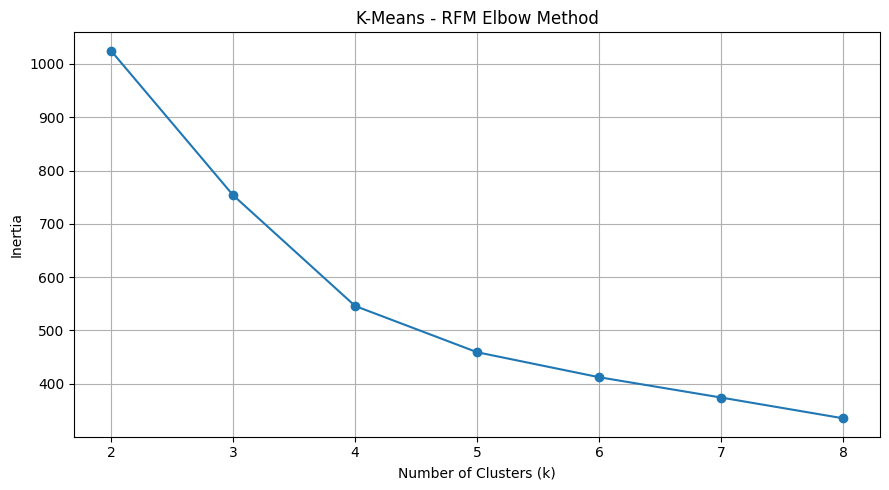

In [79]:
# Visualise inertia to identify the elbow point
plt.figure(figsize=(9, 5))
plt.plot(
    kmeans_rfm_evaluation["Clusters"],
    kmeans_rfm_evaluation["Inertia"],
    marker="o")

# Add chart labels and formatting
plt.title("K-Means - RFM Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(range(2, 9))
plt.grid(True)
plt.tight_layout()
plt.show()

In [80]:
# Create the final RFM K-Means model using two clusters
kmeans_rfm_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10)

# Assign each share to its K-Means cluster
rfm_clustering_data["KMeans_RFM_Cluster"] = (
    kmeans_rfm_model.fit_predict(X_rfm_scaled))

# Display the number of shares in each cluster
print("RFM K-Means Cluster Sizes:")
print(
    rfm_clustering_data["KMeans_RFM_Cluster"]
    .value_counts()
    .sort_index())

RFM K-Means Cluster Sizes:
KMeans_RFM_Cluster
0     83
1    405
Name: count, dtype: int64


In [81]:
# Calculate the average RFM values for each cluster
kmeans_rfm_profile = rfm_clustering_data.groupby("KMeans_RFM_Cluster").agg(
    Number_of_Shares=("Ticker", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")).round(2)

# Display the cluster profiles
display(kmeans_rfm_profile)

,Number_of_Shares,Average_Recency,Average_Frequency,Average_Monetary
KMeans_RFM_Cluster,,,,
0,83,49.61,2.45,5.208931e+10
1,405,12.17,3.19,3.310296e+10


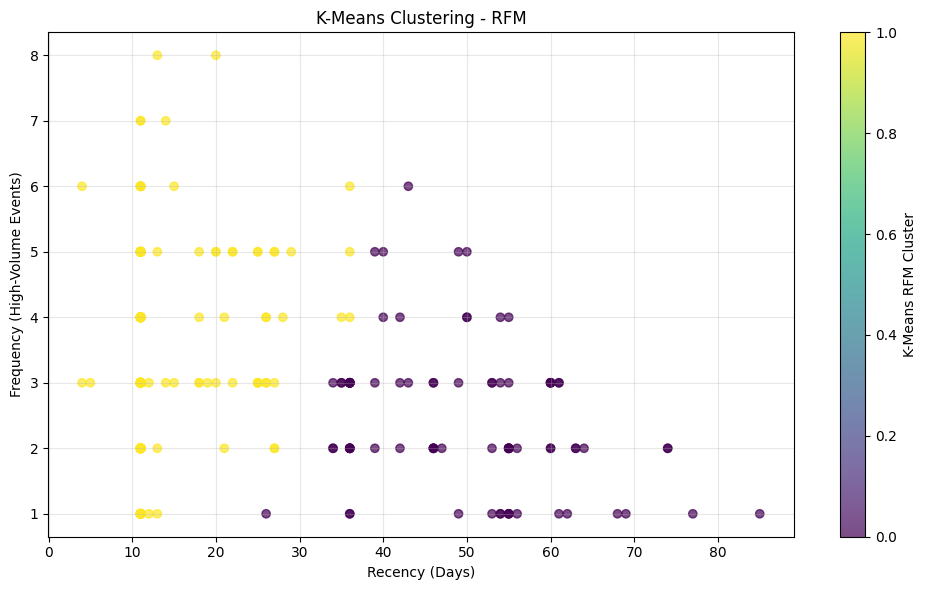

In [82]:
# Create a scatter plot to visualise RFM clusters
plt.figure(figsize=(10, 6))
plt.scatter(
    rfm_clustering_data["Recency"],
    rfm_clustering_data["Frequency"],
    c=rfm_clustering_data["KMeans_RFM_Cluster"],
    cmap="viridis",
    alpha=0.7)

# Add chart labels and formatting
plt.title("K-Means Clustering - RFM")
plt.xlabel("Recency (Days)")
plt.ylabel("Frequency (High-Volume Events)")
plt.colorbar(label="K-Means RFM Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Question 2.4

In [83]:
# Import the Adjusted Rand Index
from sklearn.metrics import adjusted_rand_score

# Compare Ward and K-Means for Risk-Return clustering
ari_risk = adjusted_rand_score(
    risk_return_data["Ward_Risk_Cluster"],
    risk_return_data["KMeans_Risk_Cluster"])

# Compare Ward and K-Means for RFM clustering
ari_rfm = adjusted_rand_score(
    rfm_clustering_data["Ward_RFM_Cluster"],
    rfm_clustering_data["KMeans_RFM_Cluster"])

# Display the ARI scores
print("Risk-Return ARI:", round(ari_risk, 4))
print("RFM ARI:", round(ari_rfm, 4))

# Display how the algorithms' cluster assignments overlap
print("\nRisk-Return Cluster Comparison:")
display(pd.crosstab(
    risk_return_data["Ward_Risk_Cluster"],
    risk_return_data["KMeans_Risk_Cluster"]))

print("\nRFM Cluster Comparison:")
display(pd.crosstab(
    rfm_clustering_data["Ward_RFM_Cluster"],
    rfm_clustering_data["KMeans_RFM_Cluster"]))

Risk-Return ARI: 0.9178
RFM ARI: 0.8639

Risk-Return Cluster Comparison:


KMeans_Risk_Cluster,0,1
Ward_Risk_Cluster,,
0,10,145
1,333,0



RFM Cluster Comparison:


KMeans_RFM_Cluster,0,1
Ward_RFM_Cluster,,
0,5,396
1,78,9


Question 2.5

,Recency,Frequency,Log_Monetary
Recency,1.0000,-0.1915,0.1262
Frequency,-0.1915,1.0000,0.0395
Log_Monetary,0.1262,0.0395,1.0000


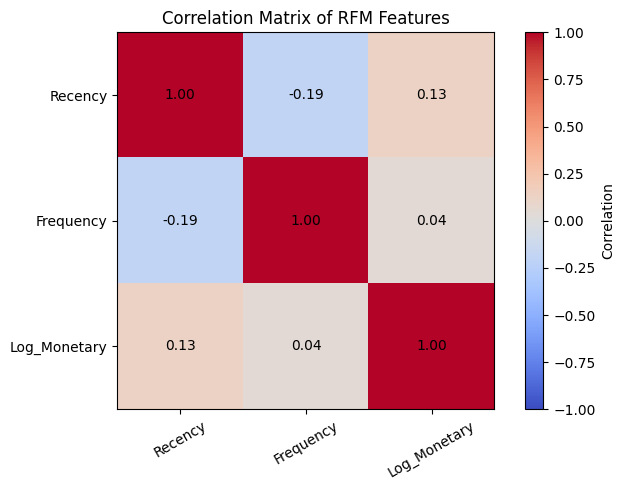

In [84]:
# Calculate correlations between the RFM features
rfm_correlation = rfm_transformed[
    ["Recency", "Frequency", "Log_Monetary"]].corr()

# Display the correlation matrix
display(rfm_correlation.round(4))

# Visualise the correlations
plt.figure(figsize=(7, 5))
plt.imshow(rfm_correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(3), rfm_correlation.columns, rotation=30)
plt.yticks(range(3), rfm_correlation.columns)

# Add correlation values to the heatmap
for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{rfm_correlation.iloc[i, j]:.2f}", ha="center", va="center")

plt.title("Correlation Matrix of RFM Features")
plt.tight_layout()
plt.show()

In [85]:
# Select only Recency and Frequency
X_rf = rfm_clustering_data[["Recency", "Frequency"]].copy()

# Standardise the two features
rf_scaler = StandardScaler()
X_rf_scaled = rf_scaler.fit_transform(X_rf)

# Apply Ward hierarchical clustering with k=2
ward_rf_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward",
    metric="euclidean")

# Store the new cluster assignments
rfm_clustering_data["Ward_RF_Cluster"] = ward_rf_model.fit_predict(X_rf_scaled)

# Display the new cluster sizes
print("Ward RF Cluster Sizes:")
display(rfm_clustering_data["Ward_RF_Cluster"].value_counts().sort_index())

Ward RF Cluster Sizes:


,count
Ward_RF_Cluster,
0,398
1,90


In [86]:
# Compare original RFM clusters with RF-only clusters
ari_rf = adjusted_rand_score(
    rfm_clustering_data["Ward_RFM_Cluster"],
    rfm_clustering_data["Ward_RF_Cluster"])

# Display the ARI score
print("Ward RFM vs Ward RF ARI:", round(ari_rf, 4))

# Compare individual cluster assignments
print("\nCluster Comparison:")
display(pd.crosstab(
    rfm_clustering_data["Ward_RFM_Cluster"],
    rfm_clustering_data["Ward_RF_Cluster"]))

Ward RFM vs Ward RF ARI: 0.8572

Cluster Comparison:


Ward_RF_Cluster,0,1
Ward_RFM_Cluster,,
0,392,9
1,6,81


In [87]:
# Compare original Monetary values across the original RFM clusters
rfm_monetary_profile = rfm_clustering_data.groupby(
    "Ward_RFM_Cluster").agg(
    Number_of_Shares=("Ticker", "count"),
    Average_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median"))

# Compare original Monetary values across the RF-only clusters
rf_monetary_profile = rfm_clustering_data.groupby(
    "Ward_RF_Cluster").agg(
    Number_of_Shares=("Ticker", "count"),
    Average_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median"))

# Display both profiles in billions
rfm_monetary_profile[
    ["Average_Monetary", "Median_Monetary"]] /= 1e9

rf_monetary_profile[
    ["Average_Monetary", "Median_Monetary"]] /= 1e9

print("Monetary Profiles - Original Ward RFM:")
display(rfm_monetary_profile.round(2))

print("Monetary Profiles - Ward RF Without Monetary:")
display(rf_monetary_profile.round(2))

Monetary Profiles - Original Ward RFM:


,Number_of_Shares,Average_Monetary,Median_Monetary
Ward_RFM_Cluster,,,
0,401,37.58,15.21
1,87,30.60,21.75


Monetary Profiles - Ward RF Without Monetary:


,Number_of_Shares,Average_Monetary,Median_Monetary
Ward_RF_Cluster,,,
0,398,33.43,15.40
1,90,49.16,20.49


# TASK 3 : Business Intelligence and Critical Review

In [88]:
# Display the column names of the first Wikipedia table
print(tables[0].columns.tolist())

# Display the first five rows
display(tables[0].head())

['Symbol', 'Security', 'GICS Sector', 'GICS Sub-Industry', 'Headquarters Location', 'Date added', 'CIK', 'Founded']


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989


In [89]:
# Extract ticker and sector information
sector_data = tables[0][["Symbol", "GICS Sector"]].copy()

# Rename columns to match the clustering datasets
sector_data = sector_data.rename(columns={
    "Symbol": "Ticker",
    "GICS Sector": "Sector"})

# Merge sector information with the risk-return results
risk_sector_data = risk_return_data.merge(
    sector_data, on="Ticker", how="left")

# Merge sector information with the RFM results
rfm_sector_data = rfm_clustering_data.merge(
    sector_data, on="Ticker", how="left")

# Check whether any sectors are missing
print("Missing sectors in Risk-Return:", risk_sector_data["Sector"].isna().sum())
print("Missing sectors in RFM:", rfm_sector_data["Sector"].isna().sum())

# Display the merged datasets
display(risk_sector_data.head())
display(rfm_sector_data.head())

Missing sectors in Risk-Return: 2
Missing sectors in RFM: 2


,Ticker,Mean_Weekly_Return,Beta,Ward_Risk_Cluster,KMeans_Risk_Cluster,Sector
0,A,0.001121,1.074724,1,0,Health Care
1,AAPL,0.003930,1.174836,0,1,Information Technology
2,ABBV,0.003749,0.425366,1,0,Health Care
3,ABNB,0.001475,1.472709,0,1,Consumer Discretionary
4,ABT,0.000971,0.583543,1,0,Health Care


,Ticker,Recency,Frequency,Monetary,Ward_RFM_Cluster,KMeans_RFM_Cluster,Ward_RF_Cluster,Sector
0,A,11.0,2,1.400180e+10,0,1,0,Health Care
1,AAPL,11.0,2,6.233034e+11,0,1,0,Information Technology
2,ABBV,11.0,3,6.837054e+10,0,1,0,Health Care
3,ABNB,11.0,3,3.652850e+10,0,1,0,Consumer Discretionary
4,ABT,11.0,1,3.523027e+10,0,1,0,Health Care


In [90]:
# Identify tickers without matching sector information
print("Missing tickers in Risk-Return:")
print(risk_sector_data.loc[risk_sector_data["Sector"].isna(), "Ticker"].tolist())

print("\nMissing tickers in RFM:")
print(rfm_sector_data.loc[rfm_sector_data["Sector"].isna(), "Ticker"].tolist())

Missing tickers in Risk-Return:
['BF-B', 'BRK-B']

Missing tickers in RFM:
['BF-B', 'BRK-B']


In [91]:
# Standardise Wikipedia ticker symbols to Yahoo Finance format
sector_data["Ticker"] = sector_data["Ticker"].str.replace(
    ".", "-", regex=False)

# Merge sector information with risk-return results
risk_sector_data = risk_return_data.merge(sector_data, on="Ticker", how="left")

# Merge sector information with RFM results
rfm_sector_data = rfm_clustering_data.merge(sector_data, on="Ticker", how="left")

# Check missing sector values
print("Missing sectors in Risk-Return:", risk_sector_data["Sector"].isna().sum())
print("Missing sectors in RFM:", rfm_sector_data["Sector"].isna().sum())

Missing sectors in Risk-Return: 0
Missing sectors in RFM: 0


In [92]:
# Calculate sector counts and percentages for each clustering solution

def sector_composition(data, cluster_column):
    # Count shares in each sector within each cluster
    counts = pd.crosstab(data[cluster_column], data["Sector"])

    # Calculate sector percentages within each cluster
    percentages = pd.crosstab(data[cluster_column], data["Sector"], normalize="index") * 100
    return counts, percentages.round(2)

# Ward Risk-Return
ward_risk_counts, ward_risk_pct = sector_composition(risk_sector_data, "Ward_Risk_Cluster")

# K-Means Risk-Return
kmeans_risk_counts, kmeans_risk_pct = sector_composition(risk_sector_data, "KMeans_Risk_Cluster")

# Ward RFM
ward_rfm_counts, ward_rfm_pct = sector_composition(rfm_sector_data, "Ward_RFM_Cluster")

# K-Means RFM
kmeans_rfm_counts, kmeans_rfm_pct = sector_composition(rfm_sector_data, "KMeans_RFM_Cluster")

# Display sector percentages
print("WARD RISK-RETURN SECTOR COMPOSITION (%)")
display(ward_risk_pct)
print("K-MEANS RISK-RETURN SECTOR COMPOSITION (%)")
display(kmeans_risk_pct)
print("WARD RFM SECTOR COMPOSITION (%)")
display(ward_rfm_pct)
print("K-MEANS RFM SECTOR COMPOSITION (%)")
display(kmeans_rfm_pct)

WARD RISK-RETURN SECTOR COMPOSITION (%)


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_Risk_Cluster,,,,,,,,,,,
0,4.52,13.55,0.65,5.16,13.55,3.87,18.71,33.55,2.58,1.94,1.94
1,4.50,7.51,8.71,3.90,16.22,15.62,15.62,6.31,5.71,8.11,7.81


K-MEANS RISK-RETURN SECTOR COMPOSITION (%)


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_Risk_Cluster,,,,,,,,,,,
0,4.37,7.29,8.45,4.66,16.03,16.33,15.45,6.41,5.54,7.87,7.58
1,4.83,14.48,0.69,3.45,13.79,1.38,19.31,35.17,2.76,2.07,2.07


WARD RFM SECTOR COMPOSITION (%)


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RFM_Cluster,,,,,,,,,,,
0,4.99,8.73,6.23,4.74,14.96,12.72,17.71,13.22,3.99,7.48,5.24
1,2.30,12.64,5.75,2.30,17.24,8.05,11.49,22.99,8.05,0.00,9.20


K-MEANS RFM SECTOR COMPOSITION (%)


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RFM_Cluster,,,,,,,,,,,
0,2.41,12.05,6.02,2.41,15.66,8.43,13.25,24.10,6.02,0.00,9.64
1,4.94,8.89,6.17,4.69,15.31,12.59,17.28,13.09,4.44,7.41,5.19


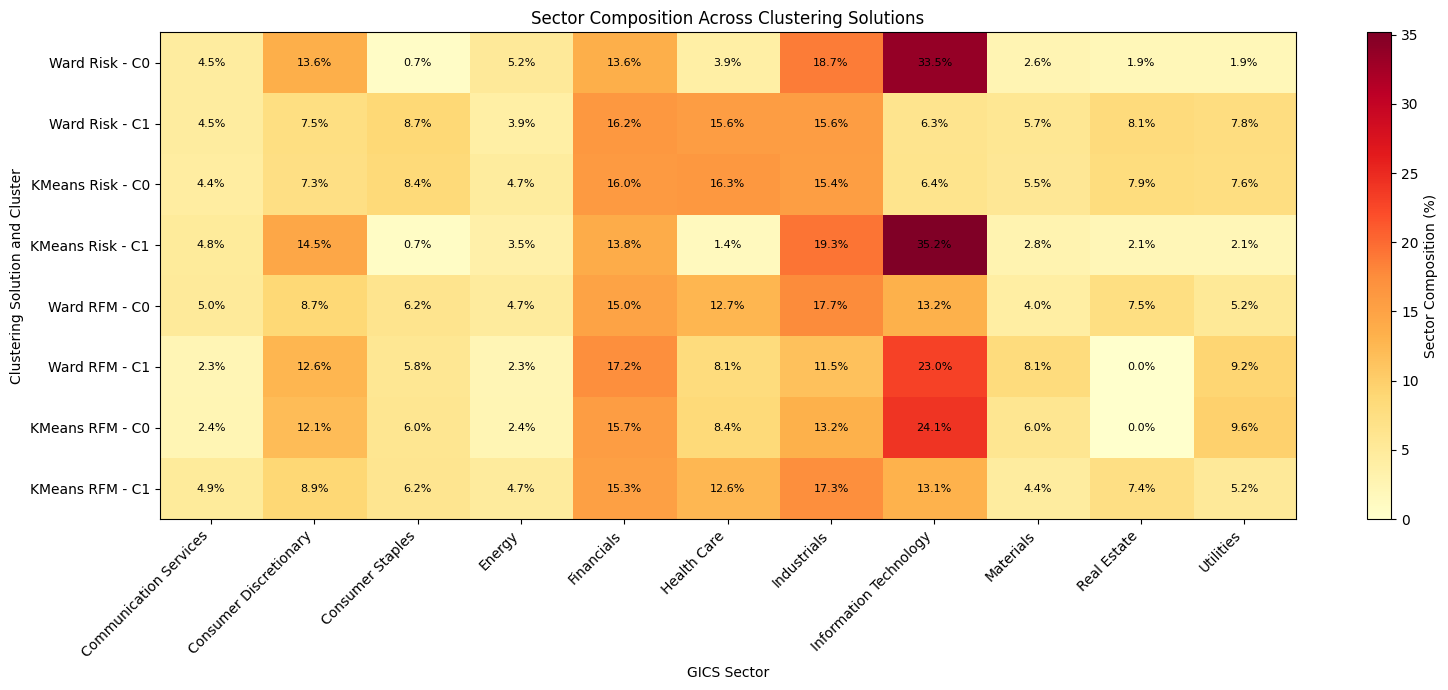

In [93]:
import matplotlib.pyplot as plt
import numpy as np

# Combine sector percentages from all four clustering solutions
sector_heatmap = pd.concat([
    ward_risk_pct.rename(index=lambda x: f"Ward Risk - C{x}"),
    kmeans_risk_pct.rename(index=lambda x: f"KMeans Risk - C{x}"),
    ward_rfm_pct.rename(index=lambda x: f"Ward RFM - C{x}"),
    kmeans_rfm_pct.rename(index=lambda x: f"KMeans RFM - C{x}")])

# Create the heatmap
fig, ax = plt.subplots(figsize=(16, 7))
image = ax.imshow(sector_heatmap.values, aspect="auto", cmap="YlOrRd")

# Add sector and cluster labels
ax.set_xticks(range(len(sector_heatmap.columns)))
ax.set_xticklabels(sector_heatmap.columns, rotation=45, ha="right")
ax.set_yticks(range(len(sector_heatmap.index)))
ax.set_yticklabels(sector_heatmap.index)

# Add percentage values inside the heatmap
for i in range(sector_heatmap.shape[0]):
    for j in range(sector_heatmap.shape[1]):
        ax.text(j, i, f"{sector_heatmap.iloc[i, j]:.1f}%", ha="center", va="center", fontsize=8)

# Add title and colour bar
ax.set_title("Sector Composition Across Clustering Solutions")
ax.set_xlabel("GICS Sector")
ax.set_ylabel("Clustering Solution and Cluster")
fig.colorbar(image, ax=ax, label="Sector Composition (%)")

plt.tight_layout()
plt.show()